# Evaluación Sumativa 2

Validación, simulación y métodos de remuestreo aplicados a los resultados de la Sumativa 1. El análisis usa semilla 42 y 10.000 remuestras, permutaciones o iteraciones.

Este notebook reúne las cinco partes en el orden del informe. Cada parte también está disponible por separado (`01_bootstrap_ic.ipynb` a `05_robustez.ipynb`). Debe ejecutarse desde la carpeta `S2` con *Restart & Run All*; la ejecución completa toma unos 3 minutos.

# 1. Validación de los intervalos de confianza mediante bootstrap

**Resultados de la S1 que se validan:** los IC 95 % clásicos de la Tabla 5 del informe de la S1 y las
diferencias de presión sistólica y de glucosa de la Tabla 4. La diferencia de presión sistólica se incluye
a pedido del docente en la retroalimentación de la S1, y la de glucosa por ser la variable más asimétrica.

| Parámetro | Estimación S1 | IC 95 % S1 | Método S1 |
| --- | --- | --- | --- |
| Edad media (años) | 49,58 | [49,32; 49,84] | t de Student |
| Presión sistólica media (mmHg) | 132,35 | [131,69; 133,02] | t de Student |
| Colesterol total medio (mg/dL), n = 4.190 | 236,70 | [235,35; 238,05] | t de Student |
| Proporción de CHD a 10 años (%) | 15,19 | [14,14; 16,30] | Wilson |
| Diferencia de presión sistólica CHD − sin CHD (mmHg) | 13,28 | [11,11; 15,45] | Welch |
| Diferencia de glucosa CHD − sin CHD (mg/dL) | 8,33 | [4,95; 11,71] | Welch |

Para cada parámetro se generan 10.000 remuestras, se calculan los IC percentil y BCa, se grafica la
distribución bootstrap y se compara con el IC clásico de la S1.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils_s2 import (
    SEED, B, ALPHA, FIG, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [2]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 1.1 Bootstrap de cada parámetro

Se generan 10.000 remuestras con reemplazo para cada estimador. En la proporción, la variable
`TenYearCHD` se trata como indicador 0/1; para colesterol se usan casos observados. La diferencia de
glucosa se calcula remuestreando de forma independiente los grupos con y sin CHD. A partir de una
misma distribución bootstrap se obtienen el IC percentil y el IC BCa; la aceleración de BCa se estima
mediante jackknife.

In [3]:
def diferencia_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


def distribucion_bootstrap_media(muestras, n_resamples=B, seed=SEED, batch=2_000):
    """Distribución bootstrap de una media o diferencia de medias, por lotes."""
    muestras = tuple(np.asarray(x, dtype=float) for x in muestras)
    rng_local = np.random.default_rng(seed)
    distribucion = np.empty(n_resamples)
    inicio = 0
    while inicio < n_resamples:
        m = min(batch, n_resamples - inicio)
        medias = []
        for x in muestras:
            indices = rng_local.integers(0, len(x), size=(m, len(x)))
            medias.append(x[indices].mean(axis=1))
        distribucion[inicio:inicio + m] = medias[0] if len(medias) == 1 else medias[0] - medias[1]
        inicio += m
    return distribucion


def jackknife_media(muestras):
    """Estimaciones leave-one-out para la corrección de aceleración BCa."""
    if len(muestras) == 1:
        x = np.asarray(muestras[0], dtype=float)
        return (x.sum() - x) / (len(x) - 1)
    a, b = (np.asarray(x, dtype=float) for x in muestras)
    jack_a = (a.sum() - a) / (len(a) - 1) - b.mean()
    jack_b = a.mean() - (b.sum() - b) / (len(b) - 1)
    return np.concatenate([jack_a, jack_b])


def intervalo_bca(distribucion, estimacion, jackknife, alpha=ALPHA):
    """IC BCa de Efron a partir de una distribución y valores jackknife."""
    proporcion = (np.sum(distribucion < estimacion) + .5 * np.sum(distribucion == estimacion)) / len(distribucion)
    proporcion = np.clip(proporcion, 1 / (2 * len(distribucion)), 1 - 1 / (2 * len(distribucion)))
    z0 = stats.norm.ppf(proporcion)
    diferencias = jackknife.mean() - jackknife
    aceleracion = np.sum(diferencias ** 3) / (6 * np.sum(diferencias ** 2) ** 1.5)
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    probabilidades = stats.norm.cdf(z0 + (z0 + z) / (1 - aceleracion * (z0 + z)))
    return np.quantile(distribucion, probabilidades)


def calcular_intervalos(nombre, muestras, estadistico, escala, referencia_s1, n_efectivo):
    """Calcula IC percentil y BCa con una única serie de 10.000 remuestras."""
    dist_sin_escala = distribucion_bootstrap_media(muestras, n_resamples=B, seed=SEED)
    estimacion_sin_escala = estadistico(*muestras, axis=-1)
    p_inf, p_sup = np.quantile(dist_sin_escala, [ALPHA / 2, 1 - ALPHA / 2])
    b_inf, b_sup = intervalo_bca(
        dist_sin_escala, estimacion_sin_escala, jackknife_media(muestras)
    )
    dist = dist_sin_escala * escala
    estimacion = estadistico(*muestras, axis=-1) * escala
    return {
        "Parámetro": nombre,
        "n": n_efectivo,
        "Estimación": float(estimacion),
        "S1_inf": referencia_s1[0],
        "S1_sup": referencia_s1[1],
        "Percentil_inf": float(p_inf * escala),
        "Percentil_sup": float(p_sup * escala),
        "BCa_inf": float(b_inf * escala),
        "BCa_sup": float(b_sup * escala),
        "Distribución": np.asarray(dist, dtype=float),
    }


edad = df["age"].dropna().to_numpy()
pas = df["sysBP"].dropna().to_numpy()
colesterol = df["totChol"].dropna().to_numpy()
chd = df["TenYearCHD"].dropna().to_numpy()
pas_chd = df.loc[df["TenYearCHD"] == 1, "sysBP"].dropna().to_numpy()
pas_no = df.loc[df["TenYearCHD"] == 0, "sysBP"].dropna().to_numpy()
glu_chd = df.loc[df["TenYearCHD"] == 1, "glucose"].dropna().to_numpy()
glu_no = df.loc[df["TenYearCHD"] == 0, "glucose"].dropna().to_numpy()

resultados = [
    calcular_intervalos(
        "Edad media (años)", (edad,), np.mean, 1,
        RESULTADOS_S1["ic"]["edad_media"]["ic"], len(edad)
    ),
    calcular_intervalos(
        "PAS media (mmHg)", (pas,), np.mean, 1,
        RESULTADOS_S1["ic"]["sysbp_media"]["ic"], len(pas)
    ),
    calcular_intervalos(
        "Colesterol medio (mg/dL)", (colesterol,), np.mean, 1,
        RESULTADOS_S1["ic"]["colesterol_media"]["ic"], len(colesterol)
    ),
    calcular_intervalos(
        "Proporción CHD (%)", (chd,), np.mean, 100,
        RESULTADOS_S1["ic"]["prop_chd_%"]["ic"], len(chd)
    ),
    calcular_intervalos(
        "Diferencia PAS CHD − no CHD", (pas_chd, pas_no), diferencia_medias, 1,
        RESULTADOS_S1["diferencias"]["sysBP"]["ic"], f"{len(pas_chd)} / {len(pas_no)}"
    ),
    calcular_intervalos(
        "Diferencia glucosa CHD − no CHD", (glu_chd, glu_no), diferencia_medias, 1,
        RESULTADOS_S1["diferencias"]["glucose"]["ic"], f"{len(glu_chd)} / {len(glu_no)}"
    ),
]

pd.DataFrame([{k: v for k, v in r.items() if k != "Distribución"} for r in resultados]).round(3)


,Parámetro,n,Estimación,S1_inf,S1_sup,Percentil_inf,Percentil_sup,BCa_inf,BCa_sup
0,Edad media (años),4240,49.5800,49.3200,49.8400,49.3210,49.8450,49.3230,49.8470
1,PAS media (mmHg),4240,132.3550,131.6900,133.0200,131.6940,133.0170,131.6970,133.0190
2,Colesterol medio (mg/dL),4190,236.7000,235.3500,238.0500,235.3640,238.0490,235.3640,238.0490
3,Proporción CHD (%),4240,15.1890,14.1400,16.3000,14.1040,16.2500,14.1510,16.2740
4,Diferencia PAS CHD − no CHD,644 / 3596,13.2810,11.1100,15.4500,11.0930,15.5290,11.1400,15.6010
5,Diferencia glucosa CHD − no CHD,594 / 3258,8.3290,4.9500,11.7100,5.0990,11.8260,5.3190,12.1580


## 1.2 Distribuciones bootstrap

Cada panel muestra la distribución bootstrap del estimador, la estimación puntual y los tres IC al 95 %:
el clásico de la S1, el percentil y el BCa.

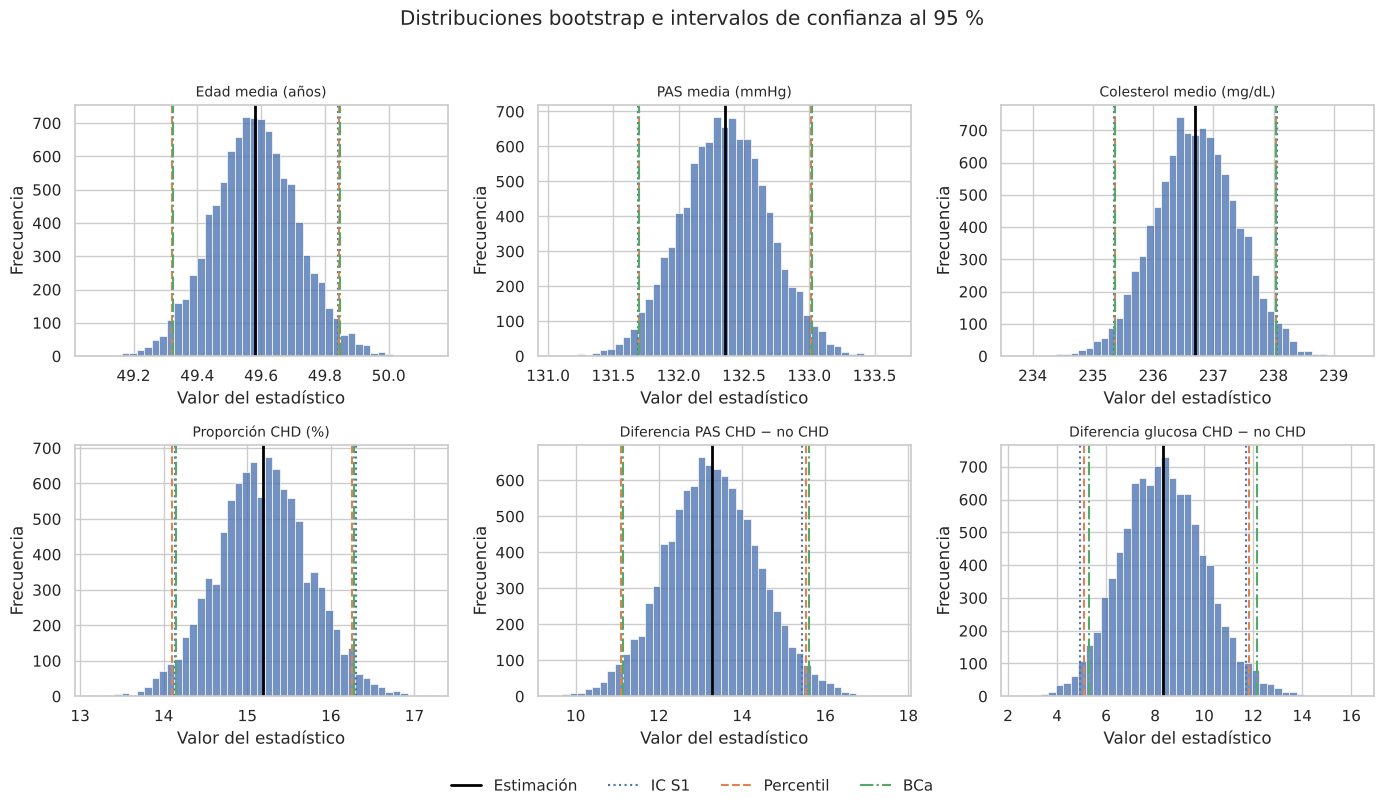

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, r in zip(axes.flat, resultados):
    sns.histplot(r["Distribución"], bins=45, color=COLORES["principal"], alpha=.78, ax=ax)
    ax.axvline(r["Estimación"], color="black", lw=2, label="Estimación")
    ax.axvline(r["S1_inf"], color=COLORES["clasico"], lw=1.5, ls=":", label="IC S1")
    ax.axvline(r["S1_sup"], color=COLORES["clasico"], lw=1.5, ls=":")
    ax.axvline(r["Percentil_inf"], color=COLORES["percentil"], lw=1.5, ls="--", label="Percentil")
    ax.axvline(r["Percentil_sup"], color=COLORES["percentil"], lw=1.5, ls="--")
    ax.axvline(r["BCa_inf"], color=COLORES["bca"], lw=1.5, ls="-.", label="BCa")
    ax.axvline(r["BCa_sup"], color=COLORES["bca"], lw=1.5, ls="-.")
    ax.set_title(r["Parámetro"], fontsize=10)
    ax.set(xlabel="Valor del estadístico", ylabel="Frecuencia")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
plt.suptitle("Distribuciones bootstrap e intervalos de confianza al 95 %", y=.995)
plt.tight_layout(rect=[0, .05, 1, .97])
plt.savefig(FIG / "p1_fig1_distribuciones_bootstrap.png", dpi=200, bbox_inches="tight")
plt.show()


## 1.3 Comparación sistemática con los IC de la S1

Para cada parámetro se comparan los límites y la amplitud de los tres intervalos, y cuánto se desplaza
el IC BCa respecto del IC clásico.

In [5]:
tabla = pd.DataFrame([{k: v for k, v in r.items() if k != "Distribución"} for r in resultados])
tabla["Amplitud_S1"] = tabla["S1_sup"] - tabla["S1_inf"]
tabla["Amplitud_percentil"] = tabla["Percentil_sup"] - tabla["Percentil_inf"]
tabla["Amplitud_BCa"] = tabla["BCa_sup"] - tabla["BCa_inf"]
tabla["Desplazamiento_BCa_vs_S1_inf"] = tabla["BCa_inf"] - tabla["S1_inf"]
tabla["Desplazamiento_BCa_vs_S1_sup"] = tabla["BCa_sup"] - tabla["S1_sup"]
tabla = tabla.set_index("Parámetro")
guardar_tabla(tabla.round(3), "p1_comparacion_ic")


,n,Estimación,S1_inf,S1_sup,Percentil_inf,Percentil_sup,BCa_inf,BCa_sup,Amplitud_S1,Amplitud_percentil,Amplitud_BCa,Desplazamiento_BCa_vs_S1_inf,Desplazamiento_BCa_vs_S1_sup
Parámetro,,,,,,,,,,,,,
Edad media (años),4240,49.5800,49.3200,49.8400,49.3210,49.8450,49.3230,49.8470,0.5200,0.5240,0.5240,0.0030,0.0070
PAS media (mmHg),4240,132.3550,131.6900,133.0200,131.6940,133.0170,131.6970,133.0190,1.3300,1.3230,1.3220,0.0070,-0.0010
Colesterol medio (mg/dL),4190,236.7000,235.3500,238.0500,235.3640,238.0490,235.3640,238.0490,2.7000,2.6850,2.6850,0.0140,-0.0010
Proporción CHD (%),4240,15.1890,14.1400,16.3000,14.1040,16.2500,14.1510,16.2740,2.1600,2.1460,2.1230,0.0110,-0.0260
Diferencia PAS CHD − no CHD,644 / 3596,13.2810,11.1100,15.4500,11.0930,15.5290,11.1400,15.6010,4.3400,4.4360,4.4610,0.0300,0.1510
Diferencia glucosa CHD − no CHD,594 / 3258,8.3290,4.9500,11.7100,5.0990,11.8260,5.3190,12.1580,6.7600,6.7260,6.8390,0.3690,0.4480


## 1.4 Discusión

Los IC percentil y BCa de la edad, la presión sistólica, el colesterol y la proporción de CHD son
prácticamente iguales a los IC clásicos de la S1. Con tamaños muestrales cercanos a 4.000, el
Teorema Central del Límite estabiliza la distribución de las medias; en la proporción, Wilson y
bootstrap también concuerdan.

La diferencia de presión sistólica entre los grupos con y sin CHD, que el docente pidió remuestrear,
también se valida: el IC BCa de [11,14; 15,60] mmHg es casi igual al IC de Welch de la S1 ([11,11; 15,45]).
Su distribución bootstrap es casi simétrica, por lo que los tres métodos coinciden y la magnitud de
13,28 mmHg no depende del supuesto de normalidad.

La glucosa es el caso que exige cautela. La distribución presenta una cola derecha muy marcada y
valores extremos (máximos cercanos a 400 mg/dL), especialmente en el grupo con CHD. Welch construye
un intervalo simétrico alrededor de la diferencia observada mediante un error estándar, mientras que
BCa corrige el sesgo y la aceleración revelados por el remuestreo; por eso su límite superior se
desplaza hacia valores mayores y el intervalo queda asimétrico. No es una contradicción: los tres
intervalos excluyen cero y sostienen que la media de glucosa es mayor en el grupo con CHD, pero BCa
describe mejor la incertidumbre asimétrica. Aun así, el promedio de glucosa es sensible a extremos y
tiene 388 datos faltantes, de modo que conviene informar también medianas o medias recortadas y
repetir el análisis tras un tratamiento explícito de faltantes en la Sumativa 3.


# 2. Validación de las pruebas de hipótesis mediante permutación

**Resultados de la S1 que se validan (sección 4 del informe):**

| Prueba S1 | Estadístico | Valor p S1 | Decisión S1 |
| --- | --- | --- | --- |
| 1. Presión sistólica según CHD (Welch) | t = 12,01; gl = 783,8; diferencia = 13,28 mmHg | < 0,001 | Se rechaza H₀ |
| 2. Tabaquismo y CHD (χ² con Yates) | χ² = 1,50; gl = 1; tasas 15,9 % vs 14,5 % | 0,221 | No se rechaza H₀ |

**Idea del test de permutación.** Si H₀ es cierta (no hay relación entre la etiqueta de grupo y la variable
respuesta), las etiquetas son *intercambiables*: cualquier reasignación de ellas es igual de probable que la
observada. Se reasignan las etiquetas al azar B = 10.000 veces con `rng.permutation`, se recalcula el
estadístico en cada reasignación y se obtiene su distribución nula sin suponer normalidad ni usar
aproximaciones asintóticas. El valor p es la proporción de estadísticos permutados al menos tan extremos
como el observado, con la corrección (k + 1)/(B + 1) de `p_valor_permutacion` (el p mínimo es 1/10.001).
Como el p de permutación es a su vez una estimación Monte Carlo, se informa su error estándar
√(p(1 − p)/B) y se verifica su convergencia.

## Configuración

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable

from utils_s2 import (
    SEED, B, ALPHA, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [7]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


### Funciones de apoyo

Para no guardar una matriz de 10.000 × 4.240 en memoria, las permutaciones se generan por lotes: cada fila
del lote es una permutación independiente de las etiquetas (`rng.permuted` aplica `rng.permutation` fila a
fila). Con una matriz de etiquetas 0/1, las sumas por grupo se obtienen con un producto matricial, lo que
permite calcular a la vez la diferencia de medias y el t de Welch de cada permutación.

In [8]:
def permutaciones_por_lotes(etiquetas, n_perm=B, rng=rng, lote=1_000):
    # Genera lotes de etiquetas permutadas (cada fila es una permutación independiente)
    etiquetas = np.asarray(etiquetas)
    hechas = 0
    while hechas < n_perm:
        m = min(lote, n_perm - hechas)
        yield rng.permuted(np.tile(etiquetas, (m, 1)), axis=1)
        hechas += m


def resumen_grupos(L, x):
    # Medias y varianzas de los grupos etiqueta = 1 y etiqueta = 0 para cada fila de L
    L = L.astype(float)
    n1 = L.sum(axis=-1)
    n0 = L.shape[-1] - n1
    s1, s0 = L @ x, (1 - L) @ x
    q1, q0 = L @ x**2, (1 - L) @ x**2
    m1, m0 = s1 / n1, s0 / n0
    v1 = (q1 - n1 * m1**2) / (n1 - 1)
    v0 = (q0 - n0 * m0**2) / (n0 - 1)
    return m1, m0, v1, v0, n1, n0


def dif_y_welch(L, x):
    # Diferencia de medias (grupo 1 - grupo 0) y estadístico t de Welch
    m1, m0, v1, v0, n1, n0 = resumen_grupos(L, x)
    dif = m1 - m0
    return dif, dif / np.sqrt(v1 / n1 + v0 / n0)


def ee_mc(p, n=B):
    # Error estándar Monte Carlo de un valor p estimado con n permutaciones
    return np.sqrt(p * (1 - p) / n)


def fmt_p(p):
    return "< 0,0001" if p < 1e-4 else f"{p:.4f}".replace(".", ",")

## 2.1 Prueba 1: presión sistólica y CHD

- **H₀:** la presión sistólica tiene la misma distribución en quienes desarrollan y no desarrollan CHD
  (las etiquetas `TenYearCHD` son intercambiables respecto de `sysBP`).
- **H₁:** la presión sistólica difiere entre ambos grupos (bilateral, α = 0,05).

Se usan dos estadísticos sobre las mismas 10.000 permutaciones: la **diferencia de medias**
(con CHD − sin CHD), que es la magnitud reportada en la S1, y el **t de Welch**, que es el estadístico de la
prueba original. El t studentizado es preferible como estadístico de permutación cuando las varianzas de
los grupos difieren (Levene rechazó la homogeneidad en la S1), porque mantiene el test válido aunque la
H₀ de intercambiabilidad completa no se cumpla y solo se quiera contrastar la igualdad de medias.

In [9]:
pas = df["sysBP"].to_numpy(float)
chd = df["TenYearCHD"].to_numpy(int)

dif_obs, t_obs = dif_y_welch(chd[None, :], pas)
dif_obs, t_obs = dif_obs.item(), t_obs.item()
welch = stats.ttest_ind(pas[chd == 1], pas[chd == 0], equal_var=False)
assert round(dif_obs, 2) == RESULTADOS_S1["pruebas"]["sysbp_chd"]["dif"]
assert round(welch.statistic, 2) == RESULTADOS_S1["pruebas"]["sysbp_chd"]["estadistico"]

nula_dif_pas, nula_t_pas = [], []
for L in permutaciones_por_lotes(chd):
    d, t = dif_y_welch(L, pas)
    nula_dif_pas.append(d)
    nula_t_pas.append(t)
nula_dif_pas = np.concatenate(nula_dif_pas)
nula_t_pas = np.concatenate(nula_t_pas)

p_perm_dif_pas = p_valor_permutacion(dif_obs, nula_dif_pas)
p_perm_t_pas = p_valor_permutacion(t_obs, nula_t_pas)
k_pas = int(np.sum(np.abs(nula_dif_pas) >= abs(dif_obs)))
z_pas = dif_obs / nula_dif_pas.std(ddof=1)

print(f"Diferencia observada: {dif_obs:.2f} mmHg | t de Welch: {t_obs:.2f} (gl = {welch.df:.1f})")
print(f"Permutaciones con |dif*| >= |dif obs|: {k_pas} de {B:,}")
print(f"p de permutación (diferencia): {p_perm_dif_pas:.6f} | p de permutación (t de Welch): {p_perm_t_pas:.6f}")
print(f"Máximo |dif*| bajo H0: {np.abs(nula_dif_pas).max():.2f} mmHg | DE de la nula: {nula_dif_pas.std(ddof=1):.3f}")
print(f"El observado está a {z_pas:.1f} DE del centro de la distribución nula")
print(f"p paramétrico de Welch: {welch.pvalue:.2e}")

Diferencia observada: 13.28 mmHg | t de Welch: 12.01 (gl = 783.8)
Permutaciones con |dif*| >= |dif obs|: 0 de 10,000
p de permutación (diferencia): 0.000100 | p de permutación (t de Welch): 0.000100
Máximo |dif*| bajo H0: 3.43 mmHg | DE de la nula: 0.952
El observado está a 14.0 DE del centro de la distribución nula
p paramétrico de Welch: 1.25e-30


**Validación con SciPy.** Se repite el test con
`scipy.stats.permutation_test` (otra semilla y otra implementación) para comprobar que la distribución nula
manual es correcta: ambas deben tener prácticamente la misma dispersión y el mismo valor p.

In [10]:
def dif_medias(x, y, axis=-1):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)


res_scipy_pas = stats.permutation_test(
    (pas[chd == 1], pas[chd == 0]), dif_medias, permutation_type="independent",
    n_resamples=B, alternative="two-sided", vectorized=True, batch=500,
    random_state=np.random.default_rng(SEED + 1),
)
print(f"SciPy: dif = {res_scipy_pas.statistic:.2f} | p = {res_scipy_pas.pvalue:.6f} "
      f"| DE de la nula = {res_scipy_pas.null_distribution.std(ddof=1):.3f}")
print(f"Manual: DE de la nula = {nula_dif_pas.std(ddof=1):.3f}")

SciPy: dif = 13.28 | p = 0.000200 | DE de la nula = 0.948
Manual: DE de la nula = 0.952


## 2.2 Prueba 2: tabaquismo y CHD

- **H₀:** fumar (`currentSmoker`) y desarrollar CHD son independientes.
- **H₁:** existe asociación (bilateral, α = 0,05).

Estadístico principal: **diferencia de tasas de CHD** (fumadores − no fumadores). Se permuta la etiqueta
`currentSmoker` manteniendo fijos los márgenes de la tabla 2×2. Con márgenes fijos, el χ² sin corrección es
una función creciente de |diferencia de tasas|, de modo que ambos estadísticos producen exactamente el
mismo valor p de permutación; igualmente se calcula el χ² de cada permutación para comparar la
distribución nula empírica con la distribución χ²₁ teórica que usó la S1.

In [11]:
fuma = df["currentSmoker"].to_numpy(int)
y_chd = chd.astype(float)
N = len(y_chd)


def dif_tasas_y_chi2(L, y):
    # Diferencia de tasas (etiqueta 1 - etiqueta 0) y chi-cuadrado sin corrección de la tabla 2x2
    L = L.astype(float)
    n1 = L.sum(axis=-1)
    n0 = L.shape[-1] - n1
    a = L @ y                      # etiqueta 1 con CHD
    c = y.sum() - a                # etiqueta 0 con CHD
    dif = a / n1 - c / n0
    b, d = n1 - a, n0 - c
    c1, c0 = a + c, b + d
    chi2 = len(y) * (a * d - b * c) ** 2 / (n1 * n0 * c1 * c0)
    return dif, chi2


dif_tasas_obs, chi2_obs = (v.item() for v in dif_tasas_y_chi2(fuma[None, :], y_chd))

tabla_fuma = pd.crosstab(df["currentSmoker"], df["TenYearCHD"])
chi_yates = stats.chi2_contingency(tabla_fuma, correction=True)
chi_sin = stats.chi2_contingency(tabla_fuma, correction=False)
fisher = stats.fisher_exact(tabla_fuma)
assert round(chi_yates.statistic, 2) == RESULTADOS_S1["pruebas"]["fumar_chd"]["estadistico"]
assert round(chi_yates.pvalue, 3) == RESULTADOS_S1["pruebas"]["fumar_chd"]["p"]

nula_dif_fuma, nula_chi2_fuma = [], []
for L in permutaciones_por_lotes(fuma):
    d, c2 = dif_tasas_y_chi2(L, y_chd)
    nula_dif_fuma.append(d)
    nula_chi2_fuma.append(c2)
nula_dif_fuma = np.concatenate(nula_dif_fuma)
nula_chi2_fuma = np.concatenate(nula_chi2_fuma)

p_perm_fuma = p_valor_permutacion(dif_tasas_obs, nula_dif_fuma)
p_perm_chi2 = p_valor_permutacion(chi2_obs, nula_chi2_fuma, alternativa="mayor")

print(f"Tasas: fumadores {y_chd[fuma == 1].mean():.2%} | no fumadores {y_chd[fuma == 0].mean():.2%}")
print(f"Diferencia observada: {dif_tasas_obs * 100:.2f} pp | χ² sin corrección: {chi2_obs:.3f}")
print(f"p de permutación (diferencia de tasas): {p_perm_fuma:.4f} ± {ee_mc(p_perm_fuma):.4f} (EE Monte Carlo)")
print(f"p de permutación (χ²): {p_perm_chi2:.4f}")
print(f"p paramétricos: χ² con Yates (S1) = {chi_yates.pvalue:.4f} | χ² sin Yates = {chi_sin.pvalue:.4f} "
      f"| Fisher exacto = {fisher.pvalue:.4f}")

Tasas: fumadores 15.89% | no fumadores 14.50%
Diferencia observada: 1.40 pp | χ² sin corrección: 1.604
p de permutación (diferencia de tasas): 0.2103 ± 0.0041 (EE Monte Carlo)
p de permutación (χ²): 0.2103
p paramétricos: χ² con Yates (S1) = 0.2211 | χ² sin Yates = 0.2054 | Fisher exacto = 0.2147


In [12]:
res_scipy_fuma = stats.permutation_test(
    (y_chd[fuma == 1], y_chd[fuma == 0]), dif_medias, permutation_type="independent",
    n_resamples=B, alternative="two-sided", vectorized=True, batch=500,
    random_state=np.random.default_rng(SEED + 2),
)
print(f"SciPy: dif = {res_scipy_fuma.statistic * 100:.2f} pp | p = {res_scipy_fuma.pvalue:.4f}")
print(f"Diferencia manual vs SciPy: {abs(p_perm_fuma - res_scipy_fuma.pvalue):.4f} "
      f"(≈ {abs(p_perm_fuma - res_scipy_fuma.pvalue) / ee_mc(p_perm_fuma):.1f} EE Monte Carlo)")

SciPy: dif = 1.40 pp | p = 0.2168
Diferencia manual vs SciPy: 0.0065 (≈ 1.6 EE Monte Carlo)


### Convergencia del valor p de permutación

El valor p es la media de los indicadores I(|T*ᵦ| ≥ |T_obs|), por lo que su convergencia se evalúa igual que
la de cualquier estimador Monte Carlo: con la media acumulada y su banda ± 1,96 EE (`media_acumulada`).

In [13]:
indicador_fuma = (np.abs(nula_dif_fuma) >= abs(dif_tasas_obs)).astype(float)
conv_fuma = media_acumulada(indicador_fuma)
hitos = [100, 500, 1_000, 2_500, 5_000, 10_000]
tabla_conv = conv_fuma.set_index("iteracion").loc[hitos].assign(
    IC95_inf=lambda t: t["media"] - 1.96 * t["ee"],
    IC95_sup=lambda t: t["media"] + 1.96 * t["ee"],
    CV_pct=lambda t: 100 * t["ee"] / t["media"],
)
tabla_conv.index.name = "Permutaciones"
guardar_tabla(tabla_conv.round(4), "p2_convergencia_p")

,media,ee,IC95_inf,IC95_sup,CV_pct
Permutaciones,,,,,
100,0.2400,0.0429,0.1559,0.3241,17.8848
500,0.1880,0.0175,0.1537,0.2223,9.3036
1000,0.1840,0.0123,0.1600,0.2080,6.6627
2500,0.2104,0.0082,0.1944,0.2264,3.8752
5000,0.2126,0.0058,0.2013,0.2239,2.7219
10000,0.2102,0.0041,0.2022,0.2182,1.9385


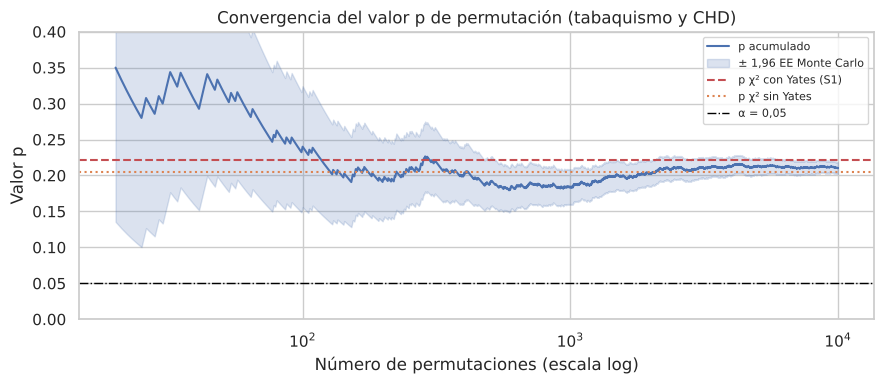

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
conv_plot = conv_fuma[conv_fuma["iteracion"] >= 20]   # las primeras iteraciones solo agregan ruido visual
k = conv_plot["iteracion"]
ax.plot(k, conv_plot["media"], color=COLORES["principal"], lw=1.5, label="p acumulado")
ax.fill_between(k, conv_plot["media"] - 1.96 * conv_plot["ee"], conv_plot["media"] + 1.96 * conv_plot["ee"],
                color=COLORES["principal"], alpha=.2, label="± 1,96 EE Monte Carlo")
ax.axhline(chi_yates.pvalue, color=COLORES["riesgo"], ls="--", lw=1.5, label="p χ² con Yates (S1)")
ax.axhline(chi_sin.pvalue, color=COLORES["percentil"], ls=":", lw=1.5, label="p χ² sin Yates")
ax.axhline(ALPHA, color="black", ls="-.", lw=1, label="α = 0,05")
ax.set_xscale("log")
ax.set_ylim(0, .4)
ax.set(xlabel="Número de permutaciones (escala log)", ylabel="Valor p",
       title="Convergencia del valor p de permutación (tabaquismo y CHD)")
ax.legend(loc="upper right", fontsize=8)
guardar_figura("p2_fig2_convergencia_p")

## 2.3 Extra: permutación estratificada por edad

En la S1 se planteó que la edad podría ocultar la asociación entre tabaquismo y CHD: los fumadores son en
promedio más jóvenes (47,7 vs 51,4 años) y la edad es el principal factor de riesgo. Para contrastarlo se
permuta `currentSmoker` **solo dentro de cada tramo de edad** (≤ 45, 46–55, > 55, los mismos de la S1). Así
la distribución nula conserva la relación edad–CHD y la edad–tabaquismo, y solo rompe la relación
tabaquismo–CHD *dentro* de cada tramo.

Estadístico: diferencia de riesgos de **Mantel-Haenszel**, Σ wₛ (p₁ₛ − p₀ₛ) / Σ wₛ con wₛ = n₁ₛ n₀ₛ / nₛ,
que promedia las diferencias de tasas de cada tramo dando más peso a los tramos con grupos más
balanceados. La referencia paramétrica es la prueba de Cochran-Mantel-Haenszel (CMH).

In [15]:
tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
codigos_tramo = tramo_edad.cat.codes.to_numpy()
indices_tramo = [np.flatnonzero(codigos_tramo == s) for s in range(3)]


def dif_mh(L, y, indices):
    # Diferencia de riesgos de Mantel-Haenszel para cada fila de etiquetas L
    L = np.atleast_2d(L).astype(float)
    num = np.zeros(L.shape[0])
    den = 0.0
    for idx in indices:
        Ls, ys = L[:, idx], y[idx]
        n1 = Ls.sum(axis=1)
        n0 = len(idx) - n1
        p1 = (Ls @ ys) / n1
        p0 = ((1 - Ls) @ ys) / n0
        w = n1 * n0 / len(idx)        # constante entre permutaciones (márgenes fijos por tramo)
        num += w * (p1 - p0)
        den = den + w
    return num / den


def permutaciones_estratificadas(etiquetas, indices, n_perm=B, rng=rng, lote=1_000):
    # Permuta las etiquetas solo dentro de cada estrato
    etiquetas = np.asarray(etiquetas)
    hechas = 0
    while hechas < n_perm:
        m = min(lote, n_perm - hechas)
        L = np.tile(etiquetas, (m, 1))
        for idx in indices:
            L[:, idx] = rng.permuted(L[:, idx], axis=1)
        yield L
        hechas += m


dif_mh_obs = dif_mh(fuma, y_chd, indices_tramo).item()
nula_mh = np.concatenate([dif_mh(L, y_chd, indices_tramo)
                          for L in permutaciones_estratificadas(fuma, indices_tramo)])
p_perm_mh = p_valor_permutacion(dif_mh_obs, nula_mh)

tablas_2x2 = np.stack([
    pd.crosstab(pd.Categorical(fuma[idx], [1, 0]), pd.Categorical(chd[idx], [1, 0])).to_numpy()
    for idx in indices_tramo
], axis=2)
cmh = StratifiedTable(tablas_2x2).test_null_odds(correction=False)
or_mh = StratifiedTable(tablas_2x2).oddsratio_pooled

print(f"Diferencia de riesgos MH (ajustada por edad): {dif_mh_obs * 100:.2f} pp "
      f"(marginal sin ajustar: {dif_tasas_obs * 100:.2f} pp)")
print(f"p de permutación estratificada: {p_perm_mh:.4f} ± {ee_mc(p_perm_mh):.4f}")
print(f"CMH: χ² = {cmh.statistic:.2f} | p = {cmh.pvalue:.4f} | OR de Mantel-Haenszel = {or_mh:.2f}")

Diferencia de riesgos MH (ajustada por edad): 4.64 pp (marginal sin ajustar: 1.40 pp)
p de permutación estratificada: 0.0001 ± 0.0001
CMH: χ² = 17.93 | p = 0.0000 | OR de Mantel-Haenszel = 1.47


**IC bootstrap por tramo.** Para completar la tabla de tasas por tramo de `resultados_validados.md` se estima
el IC 95 % BCa de la diferencia de tasas (fumadores − no fumadores) dentro de cada tramo, remuestreando
por separado a fumadores y no fumadores (10.000 remuestras).

In [16]:
filas_tramo = []
for s, (nombre, idx) in enumerate(zip(tramo_edad.cat.categories, indices_tramo)):
    y_f = y_chd[idx][fuma[idx] == 1]
    y_n = y_chd[idx][fuma[idx] == 0]
    inf, sup, _ = ic_bootstrap((y_f, y_n), dif_medias, metodo="BCa", seed=SEED + 10 + s)
    ref = RESULTADOS_S1["tasas_tramo_edad_%"][nombre]
    filas_tramo.append({
        "Tramo": nombre, "n_fumadores": len(y_f), "n_no_fumadores": len(y_n),
        "Tasa_fumadores_%": 100 * y_f.mean(), "Tasa_no_fumadores_%": 100 * y_n.mean(),
        "Tasa_fumadores_S1_%": ref["fumadores"], "Tasa_no_fumadores_S1_%": ref["no_fumadores"],
        "Dif_pp": 100 * (y_f.mean() - y_n.mean()),
        "IC95_BCa_inf_pp": 100 * inf, "IC95_BCa_sup_pp": 100 * sup,
        "Incluye_cero": inf <= 0 <= sup,
    })
tabla_tramos = pd.DataFrame(filas_tramo).set_index("Tramo")
assert np.allclose(tabla_tramos["Tasa_fumadores_%"].round(2), tabla_tramos["Tasa_fumadores_S1_%"])
guardar_tabla(tabla_tramos.drop(columns=["Tasa_fumadores_S1_%", "Tasa_no_fumadores_S1_%"]).round(2),
              "p2_tasas_tramo_edad")

,n_fumadores,n_no_fumadores,Tasa_fumadores_%,Tasa_no_fumadores_%,Dif_pp,IC95_BCa_inf_pp,IC95_BCa_sup_pp,Incluye_cero
Tramo,,,,,,,,
≤ 45,958,631,8.3500,4.1200,4.2300,1.8200,6.5400,False
46-55,721,758,18.5900,13.0600,5.5200,1.8400,9.1600,False
> 55,416,756,28.6100,24.6000,4.0000,-1.2400,9.3900,True


## 2.4 Visualización y comparación

Distribuciones nulas de permutación con el estadístico observado y los valores críticos al 5 % bilateral.

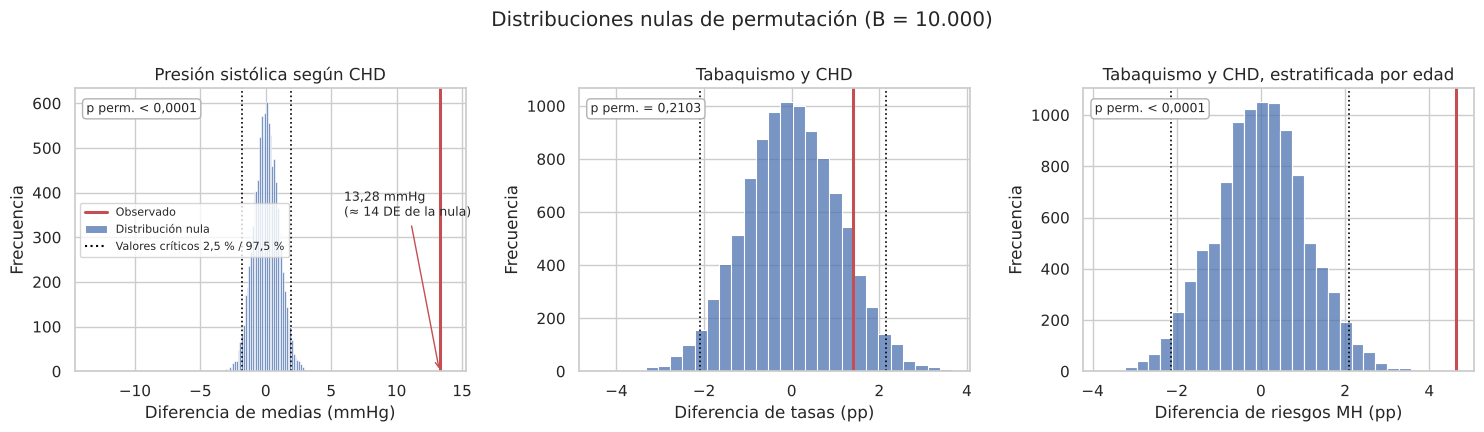

In [17]:
# La diferencia de tasas solo toma valores en una grilla de paso 1/n1 + 1/n0 (un caso de CHD que cambia de
# grupo); el ancho de barra se fija como múltiplo de ese paso para evitar un histograma "peinado".
paso_tasas = 100 * (1 / (fuma == 1).sum() + 1 / (fuma == 0).sum())
paneles = [
    (nula_dif_pas, dif_obs, "Presión sistólica según CHD", "Diferencia de medias (mmHg)", p_perm_dif_pas, None),
    (nula_dif_fuma * 100, dif_tasas_obs * 100, "Tabaquismo y CHD", "Diferencia de tasas (pp)", p_perm_fuma,
     3 * paso_tasas),
    (nula_mh * 100, dif_mh_obs * 100, "Tabaquismo y CHD, estratificada por edad",
     "Diferencia de riesgos MH (pp)", p_perm_mh, 3 * paso_tasas),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (nula, obs, titulo, xlabel, p, ancho) in zip(axes, paneles):
    opciones = {"binwidth": ancho} if ancho else {"bins": 50}
    sns.histplot(nula, color=COLORES["principal"], alpha=.75, ax=ax, label="Distribución nula", **opciones)
    crit = np.quantile(nula, [ALPHA / 2, 1 - ALPHA / 2])
    for c in crit:
        ax.axvline(c, color="black", ls=":", lw=1.2)
    ax.axvline(obs, color=COLORES["riesgo"], lw=2.2, label="Observado")
    ax.set(title=titulo, xlabel=xlabel, ylabel="Frecuencia")
    ax.text(.03, .95, "p perm. " + (fmt_p(p) if p < 1e-4 else "= " + fmt_p(p)), transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
axes[0].set_xlim(min(nula_dif_pas.min(), -dif_obs) * 1.1, dif_obs * 1.15)
axes[0].annotate(f"{dif_obs:.2f} mmHg\n(≈ {z_pas:.0f} DE de la nula)".replace(".", ","), xy=(dif_obs, 0),
                 xytext=(dif_obs * .45, axes[0].get_ylim()[1] * .55),
                 arrowprops=dict(arrowstyle="->", color=COLORES["riesgo"]), fontsize=9)
handles, labels = axes[1].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color="black", ls=":"))
labels.append("Valores críticos 2,5 % / 97,5 %")
axes[0].legend(handles, labels, loc="center left", fontsize=8, frameon=True)
plt.suptitle(f"Distribuciones nulas de permutación (B = {B:,})".replace(",", "."), y=1.0)
guardar_figura("p2_fig1_permutacion")

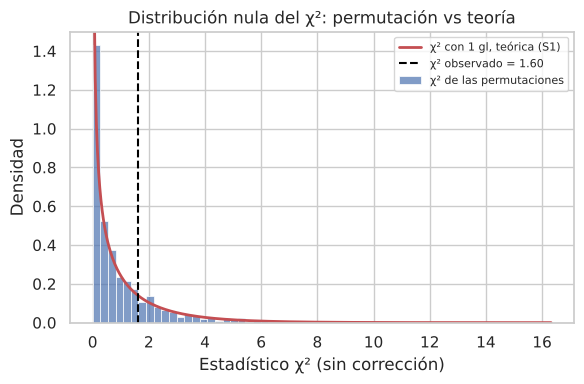

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(nula_chi2_fuma, bins=60, stat="density", color=COLORES["principal"], alpha=.7, ax=ax,
             label="χ² de las permutaciones")
xx = np.linspace(.01, nula_chi2_fuma.max(), 400)
ax.plot(xx, stats.chi2.pdf(xx, df=1), color=COLORES["riesgo"], lw=2, label="χ² con 1 gl, teórica (S1)")
ax.axvline(chi2_obs, color="black", ls="--", lw=1.5, label=f"χ² observado = {chi2_obs:.2f}")
ax.set_ylim(0, 1.5)
ax.set(xlabel="Estadístico χ² (sin corrección)", ylabel="Densidad",
       title="Distribución nula del χ²: permutación vs teoría")
ax.legend(fontsize=8)
guardar_figura("p2_fig3_chi2_nula_vs_teorica")

Tabla resumen: p paramétrico de la S1 frente al p de permutación.

In [19]:
def decision(p):
    return "Se rechaza H₀" if p < ALPHA else "No se rechaza H₀"


comparacion = pd.DataFrame([
    {"Prueba": "PAS según CHD (diferencia de medias)", "Estadístico observado": f"{dif_obs:.2f} mmHg",
     "Prueba paramétrica S1": "t de Welch", "p paramétrico": welch.pvalue,
     "p permutación": p_perm_dif_pas, "EE Monte Carlo": ee_mc(p_perm_dif_pas),
     "p SciPy": res_scipy_pas.pvalue, "Permutaciones ≥ observado": k_pas},
    {"Prueba": "PAS según CHD (t de Welch)", "Estadístico observado": f"t = {t_obs:.2f}",
     "Prueba paramétrica S1": "t de Welch", "p paramétrico": welch.pvalue,
     "p permutación": p_perm_t_pas, "EE Monte Carlo": ee_mc(p_perm_t_pas),
     "p SciPy": np.nan, "Permutaciones ≥ observado": int(np.sum(np.abs(nula_t_pas) >= abs(t_obs)))},
    {"Prueba": "Tabaquismo y CHD (diferencia de tasas)", "Estadístico observado": f"{dif_tasas_obs * 100:.2f} pp",
     "Prueba paramétrica S1": "χ² con Yates", "p paramétrico": chi_yates.pvalue,
     "p permutación": p_perm_fuma, "EE Monte Carlo": ee_mc(p_perm_fuma),
     "p SciPy": res_scipy_fuma.pvalue,
     "Permutaciones ≥ observado": int(indicador_fuma.sum())},
    {"Prueba": "Tabaquismo y CHD, estratificada por edad", "Estadístico observado": f"{dif_mh_obs * 100:.2f} pp",
     "Prueba paramétrica S1": "— (CMH como referencia)", "p paramétrico": cmh.pvalue,
     "p permutación": p_perm_mh, "EE Monte Carlo": ee_mc(p_perm_mh),
     "p SciPy": np.nan, "Permutaciones ≥ observado": int(np.sum(np.abs(nula_mh) >= abs(dif_mh_obs)))},
]).set_index("Prueba")
comparacion["Decisión paramétrica"] = comparacion["p paramétrico"].map(decision)
comparacion["Decisión permutación"] = comparacion["p permutación"].map(decision)
comparacion["¿Concuerdan?"] = np.where(
    comparacion["Decisión paramétrica"] == comparacion["Decisión permutación"], "Sí", "No")
guardar_tabla(comparacion, "p2_comparacion_p")

,Estadístico observado,Prueba paramétrica S1,p paramétrico,p permutación,EE Monte Carlo,p SciPy,Permutaciones ≥ observado,Decisión paramétrica,Decisión permutación,¿Concuerdan?
Prueba,,,,,,,,,,
PAS según CHD (diferencia de medias),13.28 mmHg,t de Welch,0.0000,0.0001,0.0001,0.0002,0,Se rechaza H₀,Se rechaza H₀,Sí
PAS según CHD (t de Welch),t = 12.01,t de Welch,0.0000,0.0001,0.0001,NaN,0,Se rechaza H₀,Se rechaza H₀,Sí
Tabaquismo y CHD (diferencia de tasas),1.40 pp,χ² con Yates,0.2211,0.2103,0.0041,0.2168,2102,No se rechaza H₀,No se rechaza H₀,Sí
"Tabaquismo y CHD, estratificada por edad",4.64 pp,— (CMH como referencia),0.0000,0.0001,0.0001,NaN,0,Se rechaza H₀,Se rechaza H₀,Sí


In [20]:
# Cifras que se citan en la discusión
print(f"PAS: p Welch = {welch.pvalue:.1e} | p permutación = {p_perm_dif_pas:.6f} (cota inferior 1/{B + 1:,})")
print(f"Tabaco: p Yates = {chi_yates.pvalue:.3f} | p sin Yates = {chi_sin.pvalue:.3f} | "
      f"p Fisher = {fisher.pvalue:.3f} | p permutación = {p_perm_fuma:.3f} ± {ee_mc(p_perm_fuma):.3f}")
print(f"Tabaco ajustado por edad: dif MH = {dif_mh_obs * 100:.2f} pp | p permutación = {p_perm_mh:.4f} "
      f"| p CMH = {cmh.pvalue:.4f}")
print(f"Media y DE de la nula del χ² permutado: {nula_chi2_fuma.mean():.3f} / {nula_chi2_fuma.std(ddof=1):.3f} "
      f"(teóricas χ²₁: 1 / {np.sqrt(2):.3f})")

PAS: p Welch = 1.2e-30 | p permutación = 0.000100 (cota inferior 1/10,001)
Tabaco: p Yates = 0.221 | p sin Yates = 0.205 | p Fisher = 0.215 | p permutación = 0.210 ± 0.004
Tabaco ajustado por edad: dif MH = 4.64 pp | p permutación = 0.0001 | p CMH = 0.0000
Media y DE de la nula del χ² permutado: 0.982 / 1.369 (teóricas χ²₁: 1 / 1.414)


## 2.5 Discusión

**Prueba 1 (presión sistólica y CHD): concordancia total.** Ninguna de las 10.000 permutaciones produjo una
diferencia tan extrema como la observada: la mayor diferencia bajo H₀ fue de 3,43 mmHg, frente a 13,28 mmHg
observados, que quedan a unas 14 desviaciones estándar del centro de la distribución nula. El p de
permutación queda en su cota inferior, 1/10.001 ≈ 0,0001. No es el p "exacto", sino el menor valor que se
puede resolver con B = 10.000. Es consistente con el p de Welch de la S1 (≈ 1,2 × 10⁻³⁰). El mismo resultado se
obtiene con el t de Welch como estadístico y con `scipy.stats.permutation_test` (la DE de la nula fue 0,952 en
la implementación manual y 0,948 en SciPy). La conclusión de la S1 se valida sin depender de la normalidad,
que la S1 había rechazado con la prueba de D'Agostino-Pearson. En este caso ambos enfoques son adecuados. Con 644 y 3.596
observaciones el Teorema Central del Límite hace que el t de Welch sea confiable pese a la asimetría, y la
permutación lo confirma sin supuestos distribucionales. El t de Welch tiene además la ventaja de entregar
un IC para la diferencia y de distinguir p muy pequeños, que la permutación no puede resolver.

**Prueba 2 (tabaquismo y CHD): concordancia en la decisión.** El p de permutación (0,210 ± 0,004 de error
Monte Carlo) está muy cerca del χ² sin corrección (0,205) y del test exacto de Fisher (0,215). Es algo menor que
el p con corrección de Yates usado en la S1 (0,221), lo que coincide con que Yates es conservador. Los cuatro
enfoques llevan a la misma decisión: no se rechaza H₀. La convergencia muestra que el p de permutación se
estabiliza desde unas 2.500 permutaciones, con un coeficiente de variación de 1,9 % al llegar a 10.000. La
distribución nula del χ² obtenida por permutación (media 0,98; DE 1,37) se parece mucho a la χ² con 1 gl
teórica (media 1; DE 1,41). Por eso, con frecuencias esperadas mínimas superiores a 300, la aproximación
asintótica de la S1 era válida. Aquí la permutación resulta más apropiada como prueba de referencia, porque
es exacta condicional a los márgenes y no depende de la aproximación χ² ni de la corrección de continuidad.
Aun así, en este caso la diferencia práctica entre ambos enfoques es nula.

**Lo que agrega la permutación estratificada.** La conclusión que no es robusta es la de "no asociación", y no
por el método de inferencia, sino por la confusión. Al permutar solo dentro de los tramos de edad, la
diferencia de riesgos ajustada sube de 1,40 pp a 4,64 pp, y ninguna permutación estratificada la alcanza
(p ≤ 0,0001, en concordancia con la prueba CMH, p < 0,0001; OR de Mantel-Haenszel = 1,47). Esto confirma con
un método no paramétrico la hipótesis de la S1: la edad enmascara el efecto del tabaquismo. Los IC bootstrap
por tramo muestran que la diferencia es positiva en los tramos ≤ 45 años (4,2 pp, IC BCa [1,8; 6,5]) y 46–55
años (5,5 pp, [1,8; 9,2]), mientras que en el tramo > 55 años (4,0 pp, [−1,2; 9,4]) el IC incluye cero. Esto se
explica porque ese tramo es el que tiene menos fumadores (416) y la mayor tasa basal de CHD.

**Síntesis y elección del método.** Las dos pruebas de la S1 se validan: las decisiones paramétricas y de
permutación coinciden en todos los casos. Para este caso de estudio, el enfoque de permutación es el más
apropiado como verificación, porque no exige normalidad ni aproximaciones asintóticas. Su versión
estratificada es la única de las pruebas aplicadas que responde a la pregunta relevante para el riesgo
coronario (¿fumar se asocia a CHD *a igual edad*?). Las limitaciones son la resolución del p (1/10.001), el
error Monte Carlo que hay que informar y el supuesto de intercambiabilidad bajo H₀, que también exige
observaciones independientes. En la siguiente fase, el efecto del tabaquismo debe estimarse ajustado por edad (por
ejemplo, con regresión logística múltiple) y no a partir de la asociación marginal.

# 3. Estabilidad de las correlaciones

**Resultado de la S1 que se valida:** correlaciones de Spearman de la sección 2.2 (Figura 3 de la S1).

| Par | ρ S1 |
| --- | --- |
| Presión sistólica – presión diastólica | 0,78 |
| Edad – presión sistólica | 0,39 |
| IMC – presión diastólica | 0,37 |
| Colesterol total – glucosa | 0,03 |
| Cigarrillos por día – glucosa | −0,09 |

## Configuración

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils_s2 import (
    SEED, B, ALPHA, FIG, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [22]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 3.1 Bootstrap de pares

Para cada par se conservan los casos completos y se remuestrean filas completas, de modo que cada
valor de una variable permanezca emparejado con su correspondiente valor de la otra. Se generan
10.000 coeficientes de Spearman por lotes y el IC percentil al 95 % se obtiene de sus cuantiles.

In [23]:
def rho_spearman(x, y):
    """Correlación de Spearman de un par."""
    return stats.spearmanr(x, y).statistic


def bootstrap_spearman(x, y, n_resamples=B, seed=SEED, batch=500):
    """Bootstrap pareado y por lotes para evitar matrices gigantes en memoria."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    rng_local = np.random.default_rng(seed)
    distribucion = np.empty(n_resamples)
    inicio = 0
    while inicio < n_resamples:
        m = min(batch, n_resamples - inicio)
        indices = rng_local.integers(0, n, size=(m, n))
        rx = stats.rankdata(x[indices], axis=1)
        ry = stats.rankdata(y[indices], axis=1)
        rx -= rx.mean(axis=1, keepdims=True)
        ry -= ry.mean(axis=1, keepdims=True)
        numerador = np.sum(rx * ry, axis=1)
        denominador = np.sqrt(np.sum(rx ** 2, axis=1) * np.sum(ry ** 2, axis=1))
        distribucion[inicio:inicio + m] = numerador / denominador
        inicio += m
    return distribucion


PARES = [
    ("sysBP", "diaBP"),
    ("age", "sysBP"),
    ("BMI", "diaBP"),
    ("totChol", "glucose"),
    ("cigsPerDay", "glucose"),
]

resultados_corr = []
distribuciones_corr = {}
for i, (x_nombre, y_nombre) in enumerate(PARES):
    datos = df[[x_nombre, y_nombre]].dropna()
    x = datos[x_nombre].to_numpy()
    y = datos[y_nombre].to_numpy()
    rho = rho_spearman(x, y)
    dist = bootstrap_spearman(x, y, seed=SEED + i)
    inferior, superior = np.quantile(dist, [ALPHA / 2, 1 - ALPHA / 2])
    etiqueta = f"{NOMBRES[x_nombre]} – {NOMBRES[y_nombre]}"
    distribuciones_corr[etiqueta] = dist
    resultados_corr.append({
        "Par": etiqueta, "n": len(datos), "rho": rho,
        "IC95_inf": inferior, "IC95_sup": superior,
        "Amplitud": superior - inferior, "Incluye_cero": inferior <= 0 <= superior,
    })

pd.DataFrame(resultados_corr).round(4)


,Par,n,rho,IC95_inf,IC95_sup,Amplitud,Incluye_cero
0,Presión sistólica (mmHg) – Presión diastólica ...,4240,0.7776,0.7631,0.7914,0.0283,False
1,Edad (años) – Presión sistólica (mmHg),4240,0.3910,0.3650,0.4169,0.0520,False
2,IMC (kg/m²) – Presión diastólica (mmHg),4221,0.3747,0.3476,0.4009,0.0532,False
3,Colesterol total (mg/dL) – Glucosa (mg/dL),3842,0.0299,-0.0015,0.0611,0.0626,True
4,Cigarrillos por día – Glucosa (mg/dL),3852,-0.0865,-0.1177,-0.0545,0.0632,False


## 3.2 Visualización

Distribuciones bootstrap de cada coeficiente e intervalos al 95 % por par, con una línea de referencia en cero.

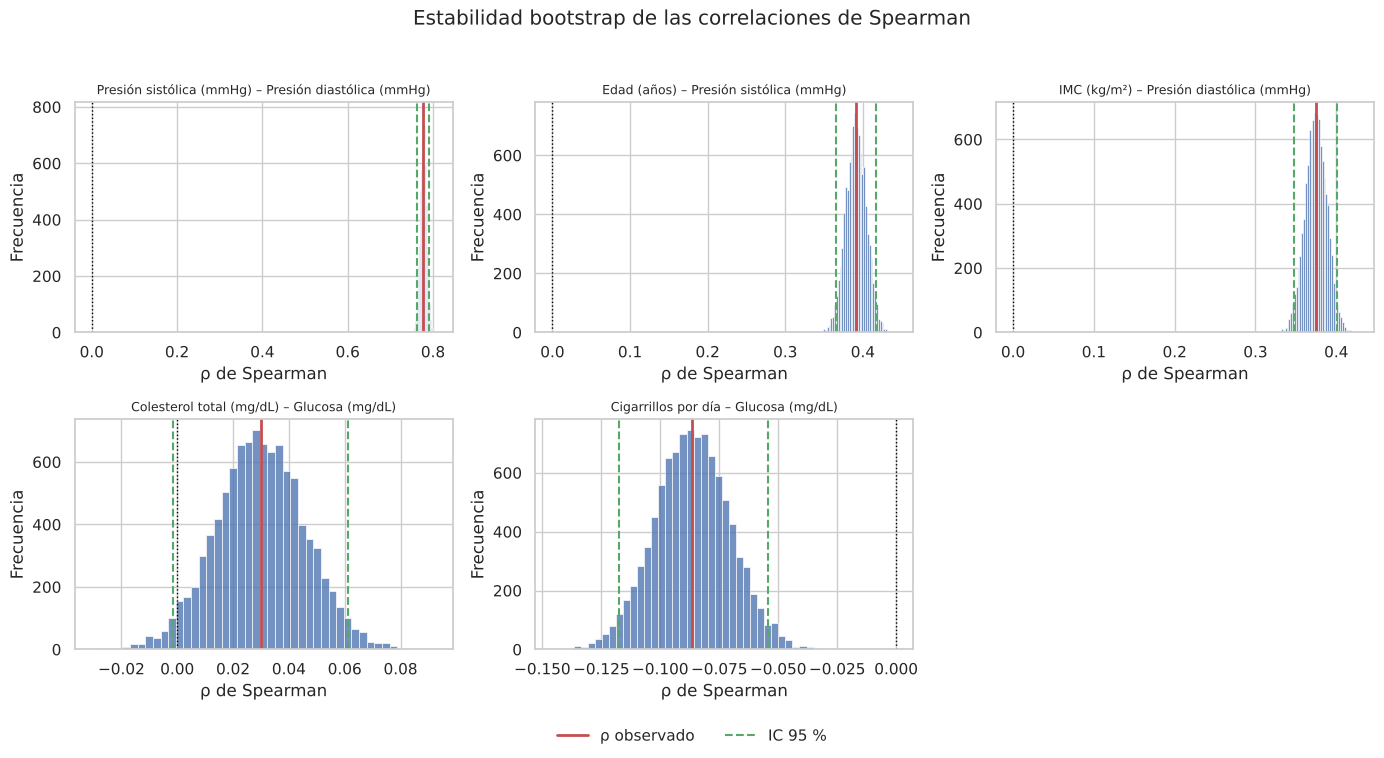

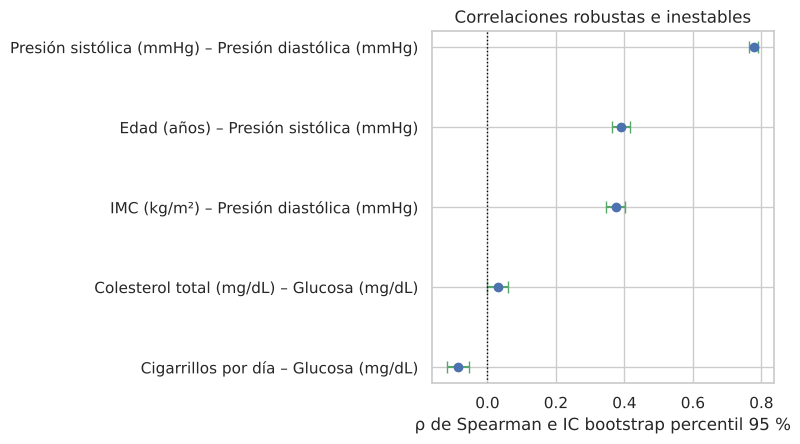

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, r in zip(axes.flat, resultados_corr):
    dist = distribuciones_corr[r["Par"]]
    sns.histplot(dist, bins=45, color=COLORES["principal"], alpha=.78, ax=ax)
    ax.axvline(0, color="black", lw=1, ls=":")
    ax.axvline(r["rho"], color=COLORES["riesgo"], lw=2, label="ρ observado")
    ax.axvline(r["IC95_inf"], color=COLORES["bca"], lw=1.5, ls="--", label="IC 95 %")
    ax.axvline(r["IC95_sup"], color=COLORES["bca"], lw=1.5, ls="--")
    ax.set_title(r["Par"], fontsize=9)
    ax.set(xlabel="ρ de Spearman", ylabel="Frecuencia")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
plt.suptitle("Estabilidad bootstrap de las correlaciones de Spearman", y=.995)
plt.tight_layout(rect=[0, .05, 1, .97])
plt.savefig(FIG / "p3_fig1_distribuciones_rho.png", dpi=200, bbox_inches="tight")
plt.show()

tabla_plot = pd.DataFrame(resultados_corr).sort_values("rho")
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(tabla_plot))
ax.errorbar(
    tabla_plot["rho"], y,
    xerr=[tabla_plot["rho"] - tabla_plot["IC95_inf"], tabla_plot["IC95_sup"] - tabla_plot["rho"]],
    fmt="o", color=COLORES["principal"], ecolor=COLORES["bca"], capsize=4
)
ax.axvline(0, color="black", lw=1, ls=":")
ax.set_yticks(y, tabla_plot["Par"])
ax.set(xlabel="ρ de Spearman e IC bootstrap percentil 95 %", ylabel="")
ax.set_title("Correlaciones robustas e inestables")
guardar_figura("p3_fig2_ic_correlaciones")


## 3.3 Clasificación: robustas vs inestables

Una correlación se considera inestable si su IC incluye cero, y de asociación débil si |ρ| < 0,10 aunque
su IC excluya cero.

In [25]:
tabla_corr = pd.DataFrame(resultados_corr)

def clasificar(fila):
    if fila["Incluye_cero"]:
        return "Inestable: compatible con 0"
    if abs(fila["rho"]) < 0.10:
        return "Dirección estable, asociación débil"
    return "Robusta"

tabla_corr["Clasificación"] = tabla_corr.apply(clasificar, axis=1)
tabla_corr = tabla_corr.set_index("Par")
guardar_tabla(tabla_corr.round(4), "p3_estabilidad_correlaciones")


,n,rho,IC95_inf,IC95_sup,Amplitud,Incluye_cero,Clasificación
Par,,,,,,,
Presión sistólica (mmHg) – Presión diastólica (mmHg),4240,0.7776,0.7631,0.7914,0.0283,False,Robusta
Edad (años) – Presión sistólica (mmHg),4240,0.3910,0.3650,0.4169,0.0520,False,Robusta
IMC (kg/m²) – Presión diastólica (mmHg),4221,0.3747,0.3476,0.4009,0.0532,False,Robusta
Colesterol total (mg/dL) – Glucosa (mg/dL),3842,0.0299,-0.0015,0.0611,0.0626,True,Inestable: compatible con 0
Cigarrillos por día – Glucosa (mg/dL),3852,-0.0865,-0.1177,-0.0545,0.0632,False,"Dirección estable, asociación débil"


## 3.4 Interpretación

Las tres correlaciones destacadas en la S1 son robustas: sus intervalos bootstrap son estrechos y no
incluyen cero. La relación entre presión sistólica y diastólica es la más estable y fuerte;
edad–presión sistólica e IMC–presión diastólica se mantienen positivas y de magnitud moderada. Entre
las asociaciones débiles, colesterol–glucosa es inestable porque su intervalo incluye cero.
Cigarrillos–glucosa conserva una dirección negativa, pero su magnitud es pequeña: estabilidad
estadística no equivale a relevancia clínica. En consecuencia, la colinealidad entre ambas presiones
sí debe considerarse en el modelamiento de la Sumativa 3, mientras que las asociaciones débiles no
justifican por sí solas decisiones de selección de variables.

# 4. Simulación Monte Carlo con los parámetros de la Sumativa 1

Se diseñan dos simulaciones que usan solo parámetros estimados en la Sumativa 1:

- **Escenario A (decisión):** casos de enfermedad coronaria a 10 años que podría evitar un programa de control
  de la hipertensión en una cohorte de 1.000 personas.
- **Escenario B (datos sintéticos):** presión sistólica generada con la media, la desviación estándar y la
  asimetría observadas en cada grupo, para evaluar si el IC y la prueba de Welch de la S1 son confiables con
  datos asimétricos como los reales.

Ambas usan 10.000 iteraciones y semilla 42. Al final se evalúa la convergencia y la sensibilidad del
escenario A a sus parámetros de entrada.

## Configuración

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from statsmodels.stats.proportion import proportion_confint

from utils_s2 import (
    SEED, B, RESULTADOS_S1, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | B = 10,000 | semilla = 42


In [27]:
# Los datos deben reproducir las cifras de la S1
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 4.1 Parámetros de entrada

Todos provienen de la S1: la prevalencia de hipertensión (Tabla 3), las tasas de CHD por grupo con su
intervalo de Wilson (Figura 4) y la presión sistólica por grupo (Tabla 4 y sección 4.1). Se recalculan desde
los datos para usar todos los decimales.

In [28]:
def proporcion(eventos, n):
    inf, sup = proportion_confint(eventos, n, alpha=0.05, method="wilson")
    return {"estimacion": eventos / n, "ic_inf": inf, "ic_sup": sup, "n": n}

hip = df["prevalentHyp"] == 1
PARAM = {
    "Prevalencia de hipertensión": proporcion(int(hip.sum()), len(df)),
    "Tasa de CHD con hipertensión": proporcion(int(df.loc[hip, "TenYearCHD"].sum()), int(hip.sum())),
    "Tasa de CHD sin hipertensión": proporcion(int(df.loc[~hip, "TenYearCHD"].sum()), int((~hip).sum())),
}
PREV = PARAM["Prevalencia de hipertensión"]["estimacion"]
P_HT = PARAM["Tasa de CHD con hipertensión"]["estimacion"]
P_NO = PARAM["Tasa de CHD sin hipertensión"]["estimacion"]

pas = df.groupby("TenYearCHD")["sysBP"].agg(n="count", media="mean", de="std", asimetria="skew")
pas.index = ["Sin CHD", "Con CHD"]

tabla_param = pd.DataFrame(PARAM).T
tabla_param[["estimacion", "ic_inf", "ic_sup"]] *= 100
display(tabla_param.round(2))
display(pas.round(2))

,estimacion,ic_inf,ic_sup,n
Prevalencia de hipertensión,31.0600,29.6900,32.4700,"4,240.0000"
Tasa de CHD con hipertensión,24.6800,22.4200,27.0800,"1,317.0000"
Tasa de CHD sin hipertensión,10.9100,9.8300,12.1000,"2,923.0000"


,n,media,de,asimetria
Sin CHD,3596,130.3400,20.4500,1.0600
Con CHD,644,143.6200,26.6900,1.0000


## 4.2 Escenario A: programa de control de la hipertensión

**Justificación.** En la S1 la hipertensión fue uno de los factores con asociación más clara con la CHD
(24,7 % frente a 10,9 %) y es modificable. Se simula una cohorte de 1.000 personas con las características de
la muestra y un programa que controla una fracción *f* de los hipertensos (20 %, 40 % y 60 %). Los controlados
pasan a tener la tasa de CHD de los no hipertensos.

**Modelo por iteración.**

1. Hipertensos: H ~ Binomial(1.000; prevalencia).
2. Controlados por el programa: C ~ Binomial(H; *f*).
3. Casos de CHD en cada grupo con su tasa. Para los controlados se usa el mismo azar en ambos escenarios
   (números aleatorios comunes): quien enfermaría con la tasa baja también enferma con la alta, y los casos
   evitados son los que solo aparecen con la tasa alta.

**Supuesto clave.** Tratar la diferencia de tasas como efecto causal del control es optimista: la asociación de
la S1 es bivariada y en parte se explica por la edad. Por eso los casos evitados se leen como un **límite
superior** del beneficio.

In [29]:
N_COHORTE = 1_000
FRACCIONES = [0.2, 0.4, 0.6]


def simular_programa(f, prev=PREV, p_ht=P_HT, p_no=P_NO, n=N_COHORTE, b=B, rng=rng):
    """Casos de CHD sin programa, con programa y evitados, en b cohortes simuladas."""
    h = rng.binomial(n, prev, b)
    c = rng.binomial(h, f)
    casos_ctrl_tasa_baja = rng.binomial(c, p_no)
    evitados = rng.binomial(c - casos_ctrl_tasa_baja, (p_ht - p_no) / (1 - p_no))
    resto = rng.binomial(h - c, p_ht) + rng.binomial(n - h, p_no)
    sin_programa = resto + casos_ctrl_tasa_baja + evitados
    return sin_programa, sin_programa - evitados, evitados


sim = {f: simular_programa(f) for f in FRACCIONES}

filas = []
for f, (sin_prog, con_prog, evit) in sim.items():
    filas.append({
        "Hipertensos controlados (%)": int(f * 100),
        "Casos sin programa (media)": sin_prog.mean(),
        "Casos con programa (media)": con_prog.mean(),
        "Casos evitados (media)": evit.mean(),
        "Evitados IC95 inf": np.percentile(evit, 2.5),
        "Evitados IC95 sup": np.percentile(evit, 97.5),
        "Reducción relativa (%)": evit.mean() / sin_prog.mean() * 100,
        "P(evitados ≥ 10)": (evit >= 10).mean(),
    })
tabla_a = pd.DataFrame(filas).set_index("Hipertensos controlados (%)")
guardar_tabla(tabla_a.round(3), "p4_escenarios_programa")

,Casos sin programa (media),Casos con programa (media),Casos evitados (media),Evitados IC95 inf,Evitados IC95 sup,Reducción relativa (%),P(evitados ≥ 10)
Hipertensos controlados (%),,,,,,,
20,151.7360,143.2060,8.5300,3.0000,15.0000,5.6220,0.3490
40,151.7220,134.6440,17.0790,10.0000,26.0000,11.2570,0.9790
60,151.8970,126.2260,25.6710,16.0000,36.0000,16.9000,1.0000


In [30]:
sin_prog = sim[0.4][0]
tasa_sim = sin_prog.mean() / N_COHORTE * 100
ic_tasa = np.percentile(sin_prog, [2.5, 97.5]) / N_COHORTE * 100
print(f"Tasa de CHD simulada sin programa: {tasa_sim:.2f} % (95 % de las cohortes entre {ic_tasa[0]:.1f} % y {ic_tasa[1]:.1f} %)")
print(f"Tasa observada en la S1: {RESULTADOS_S1['ic']['prop_chd_%']['estimacion']:.2f} % "
      f"[{RESULTADOS_S1['ic']['prop_chd_%']['ic'][0]}; {RESULTADOS_S1['ic']['prop_chd_%']['ic'][1]}]")

Tasa de CHD simulada sin programa: 15.17 % (95 % de las cohortes entre 13.0 % y 17.4 %)
Tasa observada en la S1: 15.19 % [14.14; 16.3]


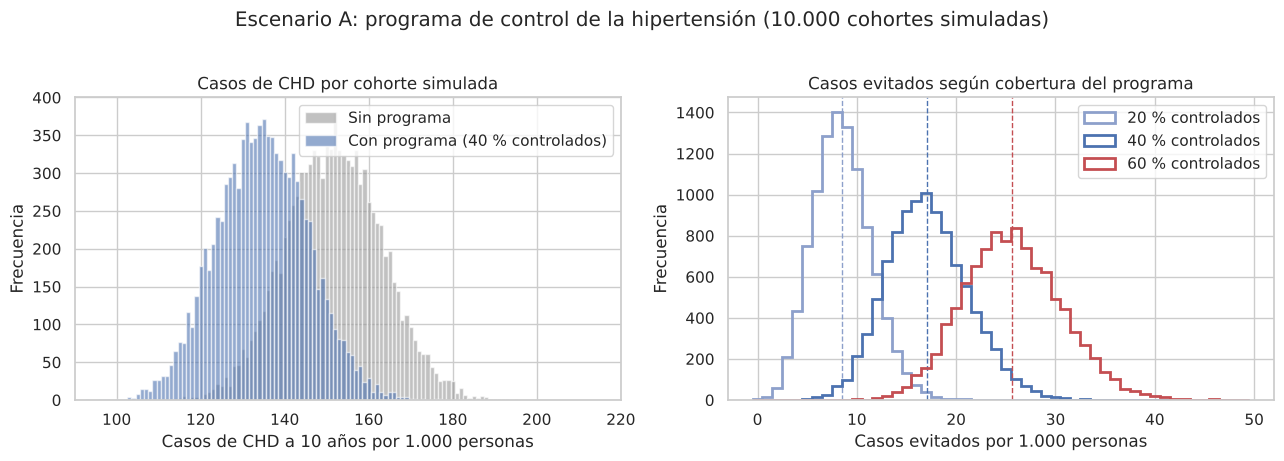

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colores_f = {0.2: COLORES["caja"], 0.4: COLORES["principal"], 0.6: COLORES["riesgo"]}

ax = axes[0]
bordes = np.arange(79.5, 230.5, 1)
ax.hist(sim[0.4][0], bins=bordes, color="0.6", alpha=0.6, label="Sin programa")
ax.hist(sim[0.4][1], bins=bordes, color=COLORES["principal"], alpha=0.6, label="Con programa (40 % controlados)")
ax.set(xlim=(90, 220), xlabel="Casos de CHD a 10 años por 1.000 personas", ylabel="Frecuencia",
       title="Casos de CHD por cohorte simulada")
ax.legend()

ax = axes[1]
bordes = np.arange(-0.5, 50.5, 1)
for f in FRACCIONES:
    evit = sim[f][2]
    ax.hist(evit, bins=bordes, histtype="step", lw=2, color=colores_f[f], label=f"{int(f*100)} % controlados")
    ax.axvline(evit.mean(), color=colores_f[f], ls="--", lw=1)
ax.set(xlabel="Casos evitados por 1.000 personas", ylabel="Frecuencia",
       title="Casos evitados según cobertura del programa")
ax.legend()
plt.suptitle(f"Escenario A: programa de control de la hipertensión ({B:,} cohortes simuladas)".replace(",", "."), y=1.02)
guardar_figura("p4_fig1_escenario_programa")

## 4.3 Escenario A con incertidumbre de los parámetros

La simulación anterior fija los parámetros en su estimación puntual. Para propagar también la incertidumbre
de la S1, en cada iteración se extraen la prevalencia y las dos tasas de una normal centrada en su estimación,
con su error estándar de la S1.

In [32]:
def sortear_parametros(b=B, rng=rng):
    def normal(clave):
        p, n = PARAM[clave]["estimacion"], PARAM[clave]["n"]
        return np.clip(rng.normal(p, np.sqrt(p * (1 - p) / n), b), 0, 1)
    prev = normal("Prevalencia de hipertensión")
    p_ht = normal("Tasa de CHD con hipertensión")
    p_no = np.minimum(normal("Tasa de CHD sin hipertensión"), p_ht)
    return prev, p_ht, p_no


prev_s, p_ht_s, p_no_s = sortear_parametros()
_, _, evit_incert = simular_programa(0.4, prev=prev_s, p_ht=p_ht_s, p_no=p_no_s)
evit_fijo = sim[0.4][2]
tabla_incert = pd.DataFrame({
    "Media": [evit_fijo.mean(), evit_incert.mean()],
    "DE": [evit_fijo.std(ddof=1), evit_incert.std(ddof=1)],
    "IC95 inf": [np.percentile(evit_fijo, 2.5), np.percentile(evit_incert, 2.5)],
    "IC95 sup": [np.percentile(evit_fijo, 97.5), np.percentile(evit_incert, 97.5)],
}, index=["Parámetros fijos", "Con incertidumbre de la S1"])
tabla_incert.index.name = "Casos evitados (40 % controlados)"
guardar_tabla(tabla_incert.round(2), "p4_incertidumbre_parametros")

,Media,DE,IC95 inf,IC95 sup
Casos evitados (40 % controlados),,,,
Parámetros fijos,17.0800,4.0900,10.0000,26.0000
Con incertidumbre de la S1,17.0200,4.4500,9.0000,26.0000


## 4.4 Escenario B: datos sintéticos de presión sistólica

**Justificación.** En la S1 la presión sistólica no es normal (asimetría ≈ 1 en ambos grupos) y la prueba de
Welch se justificó por el Teorema Central del Límite. Aquí se verifica ese supuesto: se generan muestras
sintéticas con la misma media, desviación estándar y asimetría de cada grupo, y se mide con qué frecuencia el
IC 95 % de Welch contiene la diferencia verdadera (cobertura) y con qué frecuencia la prueba la detecta
(potencia). Se repite con tamaños muestrales menores, manteniendo la proporción de casos con CHD (15,2 %).

**Generador.** Lognormal desplazada de tres parámetros, ajustada por momentos a la media, la DE y la asimetría
de cada grupo.

In [33]:
def lognormal_desplazada(media, de, asimetria):
    """Parámetros (sigma, escala, desplazamiento) con la media, DE y asimetría pedidas."""
    w = brentq(lambda w: (w + 2) * np.sqrt(w - 1) - asimetria, 1 + 1e-12, 50)
    sigma = np.sqrt(np.log(w))
    escala = de / np.sqrt((w - 1) * w)
    return sigma, escala, media - escala * np.sqrt(w)


GEN = {g: lognormal_desplazada(*pas.loc[g, ["media", "de", "asimetria"]]) for g in pas.index}


def generar(grupo, size, rng=rng):
    sigma, escala, desplaz = GEN[grupo]
    return desplaz + escala * np.exp(sigma * rng.standard_normal(size))


control = pd.DataFrame({g: (lambda x: [x.mean(), x.std(ddof=1), stats.skew(x)])(generar(g, 1_000_000))
                        for g in pas.index}, index=["media", "de", "asimetria"]).T
display(pd.concat({"Observado (S1)": pas[["media", "de", "asimetria"]], "Sintético": control}, axis=1).round(2))

Observado (S1)                   Sintético                  
                 media      de asimetria     media      de asimetria
Sin CHD       130.3400 20.4500    1.0600  130.3600 20.4400    1.0500
Con CHD       143.6200 26.6900    1.0000  143.6300 26.7000    1.0100

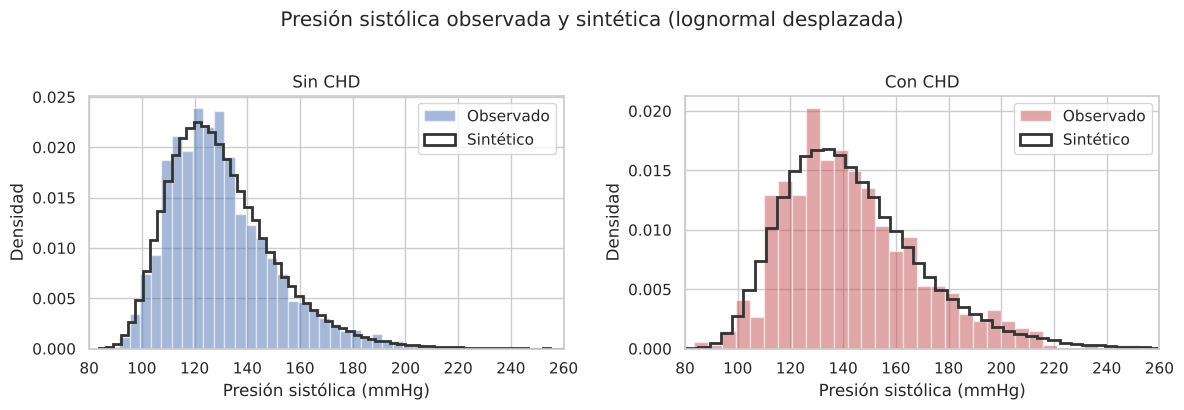

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g, color in zip(axes, pas.index, [COLORES["principal"], COLORES["riesgo"]]):
    obs = df.loc[df["TenYearCHD"] == (g == "Con CHD"), "sysBP"]
    ax.hist(obs, bins=40, density=True, alpha=0.5, color=color, label="Observado")
    ax.hist(generar(g, 200_000), bins=80, density=True, histtype="step", lw=2, color="0.2", label="Sintético")
    ax.set(xlim=(80, 260), xlabel="Presión sistólica (mmHg)", ylabel="Densidad", title=g)
    ax.legend()
plt.suptitle("Presión sistólica observada y sintética (lognormal desplazada)", y=1.02)
guardar_figura("p4_fig2_sintetico_vs_observado")

In [35]:
DIF_REAL = pas.loc["Con CHD", "media"] - pas.loc["Sin CHD", "media"]


def welch_simulado(n1, n0, b=B, bloque=500, rng=rng):
    """Cobertura del IC 95 % de Welch y rechazo de H0 en b pares de muestras sintéticas."""
    cubre, rechaza = [], []
    for _ in range(b // bloque):
        x1 = generar("Con CHD", (bloque, n1), rng)
        x0 = generar("Sin CHD", (bloque, n0), rng)
        v1, v0 = x1.var(axis=1, ddof=1) / n1, x0.var(axis=1, ddof=1) / n0
        ee = np.sqrt(v1 + v0)
        gl = (v1 + v0) ** 2 / (v1 ** 2 / (n1 - 1) + v0 ** 2 / (n0 - 1))
        t_crit = stats.t.ppf(0.975, gl)
        dif = x1.mean(axis=1) - x0.mean(axis=1)
        cubre.append(np.abs(dif - DIF_REAL) <= t_crit * ee)
        rechaza.append(np.abs(dif) / ee > t_crit)
    return np.concatenate(cubre), np.concatenate(rechaza)


TAMANOS = [(644, 3596), (150, 838), (50, 279), (20, 112), (10, 56), (5, 28)]
res_b, filas = {}, []
for n1, n0 in TAMANOS:
    cubre, rechaza = welch_simulado(n1, n0)
    res_b[(n1, n0)] = cubre
    ee_mc = np.sqrt(cubre.mean() * (1 - cubre.mean()) / B)
    filas.append({"n con CHD": n1, "n sin CHD": n0, "n total": n1 + n0,
                  "Cobertura IC 95 % (%)": cubre.mean() * 100, "EE Monte Carlo (pp)": ee_mc * 100,
                  "Potencia (%)": rechaza.mean() * 100})
tabla_b = pd.DataFrame(filas).set_index("n total")
guardar_tabla(tabla_b.round(2), "p4_cobertura_potencia")

,n con CHD,n sin CHD,Cobertura IC 95 % (%),EE Monte Carlo (pp),Potencia (%)
n total,,,,,
4240,644,3596,95.0800,0.2200,100.0000
988,150,838,94.7600,0.2200,100.0000
329,50,279,94.6400,0.2300,93.7200
132,20,112,94.7300,0.2200,52.4300
66,10,56,93.6000,0.2400,23.0800
33,5,28,92.6900,0.2600,9.7600


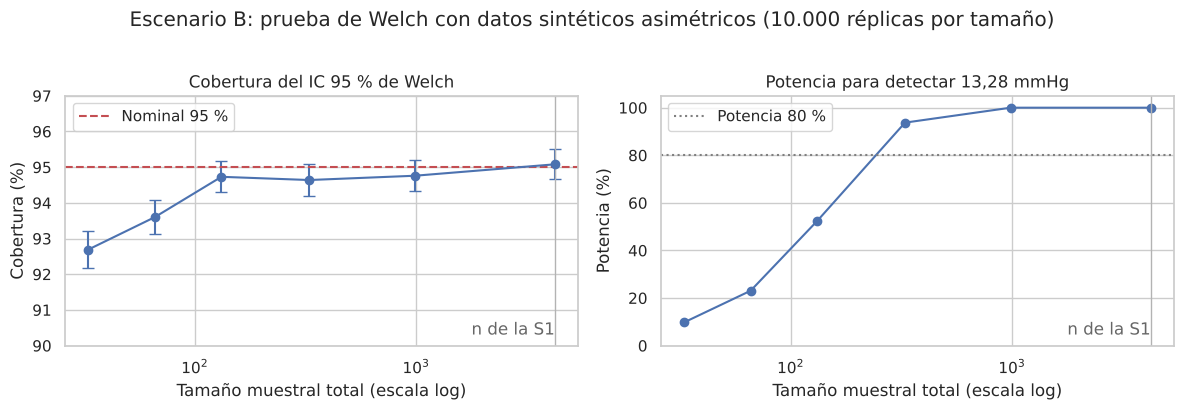

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ee = tabla_b["EE Monte Carlo (pp)"]
ax.errorbar(tabla_b.index, tabla_b["Cobertura IC 95 % (%)"], yerr=1.96 * ee, fmt="o-",
            color=COLORES["principal"], capsize=4)
ax.axhline(95, color=COLORES["riesgo"], ls="--", label="Nominal 95 %")
ax.set(xscale="log", ylim=(90, 97), xlabel="Tamaño muestral total (escala log)", ylabel="Cobertura (%)",
       title="Cobertura del IC 95 % de Welch")
ax.legend()
ax = axes[1]
ax.plot(tabla_b.index, tabla_b["Potencia (%)"], "o-", color=COLORES["principal"])
ax.axhline(80, color="0.5", ls=":", label="Potencia 80 %")
ax.set(xscale="log", ylim=(0, 105), xlabel="Tamaño muestral total (escala log)", ylabel="Potencia (%)",
       title=f"Potencia para detectar {DIF_REAL:.2f} mmHg".replace(".", ","))
ax.legend()
for a in axes:
    a.axvline(4240, color="0.7", lw=1)
    a.annotate("n de la S1", (4240, a.get_ylim()[0]), xytext=(-60, 8), textcoords="offset points", color="0.4")
plt.suptitle(f"Escenario B: prueba de Welch con datos sintéticos asimétricos ({B:,} réplicas por tamaño)".replace(",", "."), y=1.02)
guardar_figura("p4_fig3_cobertura_potencia")

## 4.5 Convergencia

Se grafica la media acumulada de los casos evitados (escenario A, 40 % controlados) y de la cobertura del
IC (escenario B, n de la S1) con su banda ±1,96 · EE Monte Carlo. La simulación converge si la media se
estabiliza y la banda se estrecha a un ancho despreciable para la interpretación.

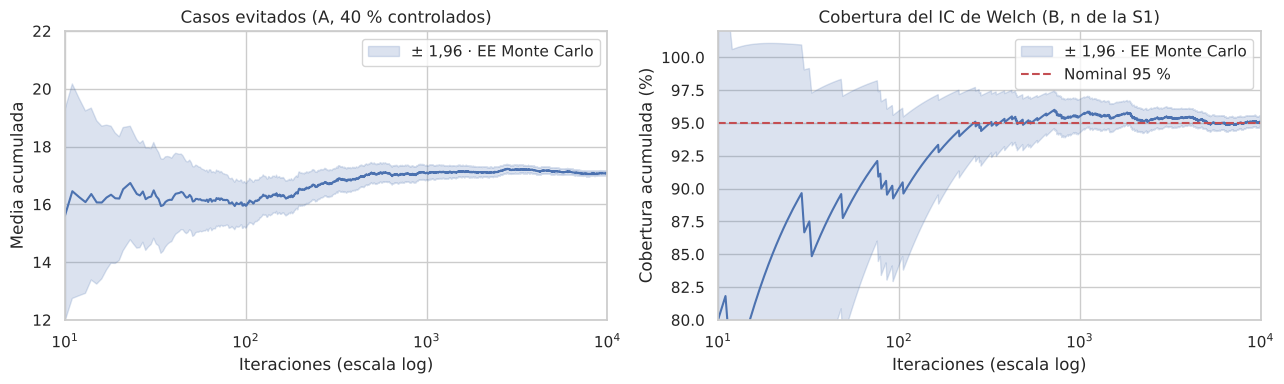

,Evitados: media,Evitados: EE,Cobertura: media (%),Cobertura: EE (pp)
Iteraciones,,,,
100,15.9500,0.3950,90.0000,3.0150
1000,17.0880,0.1300,95.5000,0.6560
5000,17.1350,0.0580,95.1200,0.3050
10000,17.0790,0.0410,95.0800,0.2160


In [37]:
conv_a = media_acumulada(sim[0.4][2])
conv_b = media_acumulada(res_b[(644, 3596)].astype(float) * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, conv, titulo, ylab, ref in [
    (axes[0], conv_a, "Casos evitados (A, 40 % controlados)", "Media acumulada", None),
    (axes[1], conv_b, "Cobertura del IC de Welch (B, n de la S1)", "Cobertura acumulada (%)", 95),
]:
    ax.plot(conv["iteracion"], conv["media"], color=COLORES["principal"])
    ax.fill_between(conv["iteracion"], conv["media"] - 1.96 * conv["ee"], conv["media"] + 1.96 * conv["ee"],
                    color=COLORES["principal"], alpha=0.2, label="± 1,96 · EE Monte Carlo")
    if ref is not None:
        ax.axhline(ref, color=COLORES["riesgo"], ls="--", label="Nominal 95 %")
        ax.set_ylim(80, 102)
    else:
        ax.set_ylim(12, 22)
    ax.set(xscale="log", xlim=(10, B), xlabel="Iteraciones (escala log)", ylabel=ylab, title=titulo)
    ax.legend()
guardar_figura("p4_fig4_convergencia")

hitos = [100, 1_000, 5_000, 10_000]
tabla_conv = pd.DataFrame({
    "Evitados: media": conv_a.set_index("iteracion").loc[hitos, "media"],
    "Evitados: EE": conv_a.set_index("iteracion").loc[hitos, "ee"],
    "Cobertura: media (%)": conv_b.set_index("iteracion").loc[hitos, "media"],
    "Cobertura: EE (pp)": conv_b.set_index("iteracion").loc[hitos, "ee"],
})
tabla_conv.index.name = "Iteraciones"
guardar_tabla(tabla_conv.round(3), "p4_convergencia")

## 4.6 Análisis de sensibilidad

Se varía cada parámetro de entrada del escenario A entre los límites de su IC 95 % de la S1, dejando los
demás en su estimación, y se registra el cambio en los casos evitados con 40 % de cobertura (gráfico de
tornado). La cobertura del programa no se incluye porque es una decisión, no un parámetro estimado; su efecto
ya se muestra en la sección 4.2.

In [38]:
claves = {"Prevalencia de hipertensión": "prev", "Tasa de CHD con hipertensión": "p_ht",
          "Tasa de CHD sin hipertensión": "p_no"}
base = sim[0.4][2].mean()
filas = []
for nombre, arg in claves.items():
    fila = {"Parámetro": nombre}
    for limite in ["ic_inf", "ic_sup"]:
        valor = PARAM[nombre][limite]
        fila[f"Valor {limite[-3:]} (%)"] = valor * 100
        fila[f"Evitados con {limite[-3:]}"] = simular_programa(0.4, **{arg: valor})[2].mean()
    filas.append(fila)
tabla_sens = pd.DataFrame(filas).set_index("Parámetro")
tabla_sens["Rango (casos)"] = (tabla_sens["Evitados con sup"] - tabla_sens["Evitados con inf"]).abs()
tabla_sens = tabla_sens.sort_values("Rango (casos)")
guardar_tabla(tabla_sens.round(2), "p4_sensibilidad")

,Valor inf (%),Evitados con inf,Valor sup (%),Evitados con sup,Rango (casos)
Parámetro,,,,,
Prevalencia de hipertensión,29.6900,16.3800,32.4700,17.8800,1.4900
Tasa de CHD sin hipertensión,9.8300,18.4800,12.1000,15.6200,2.8600
Tasa de CHD con hipertensión,22.4200,14.3200,27.0800,20.0900,5.7600


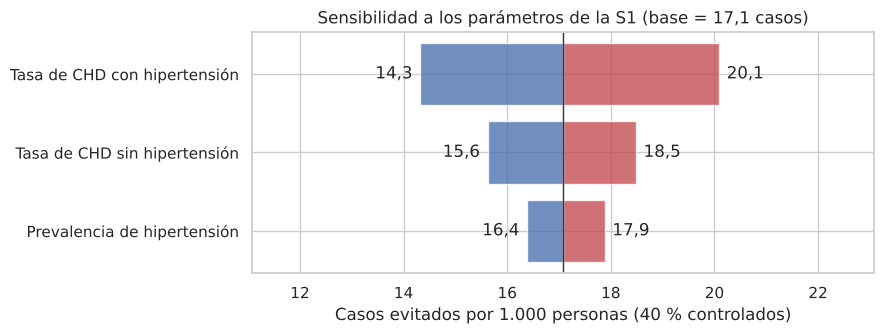

In [39]:
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(tabla_sens))
for i, (nombre, fila) in enumerate(tabla_sens.iterrows()):
    lo, hi = sorted([fila["Evitados con inf"], fila["Evitados con sup"]])
    ax.barh(i, hi - base, left=base, color=COLORES["riesgo"], alpha=0.8)
    ax.barh(i, lo - base, left=base, color=COLORES["principal"], alpha=0.8)
    ax.text(hi + 0.15, i, f"{hi:.1f}".replace(".", ","), va="center")
    ax.text(lo - 0.15, i, f"{lo:.1f}".replace(".", ","), va="center", ha="right")
ax.axvline(base, color="0.2", lw=1)
ax.set_yticks(y, tabla_sens.index)
ax.set(xlabel="Casos evitados por 1.000 personas (40 % controlados)",
       title=f"Sensibilidad a los parámetros de la S1 (base = {base:.1f} casos)".replace(".", ","))
ax.set_xlim(base - 6, base + 6)
guardar_figura("p4_fig5_tornado")

## 4.7 Interpretación

**Escenario A.** El modelo reproduce el fenómeno observado: sin programa se esperan 151,7 casos por 1.000
personas (15,17 %), prácticamente igual a la tasa de la S1 (15,19 % [14,14; 16,30]). El rango entre cohortes
(13,0 % a 17,4 %) es más amplio que el IC de la S1 porque describe cohortes de 1.000 personas y no la media
poblacional.

Los casos evitados crecen de forma lineal con la cobertura: 8,5 [3; 15] con 20 % de hipertensos controlados,
17,1 [10; 26] con 40 % y 25,7 [16; 36] con 60 %, es decir, reducciones de 5,6 %, 11,3 % y 16,9 % de los casos.
Equivale a controlar unos 7 hipertensos por cada caso evitado (1 / (24,7 % − 10,9 %)). Con 20 % de cobertura
el beneficio es incierto (solo 35 % de las cohortes evita 10 casos o más); desde 40 % lo logra el 98 %.
Agregar la incertidumbre de los parámetros de la S1 casi no cambia el resultado (DE de 4,1 a 4,5 casos): con
más de 4.000 observaciones, la variabilidad dominante es la del azar entre personas y no la de la estimación.
Estas cifras son un límite superior, porque suponen que toda la diferencia de tasas se debe a la hipertensión.

**Escenario B.** Los datos sintéticos reproducen la media, la DE y la asimetría de la presión sistólica en
ambos grupos. Con el tamaño de la S1, el IC 95 % de Welch cubre la diferencia verdadera el 95,1 % de las veces
(EE 0,2 pp) y la prueba la detecta siempre, por lo que la conclusión de la S1 (13,28 mmHg, p < 0,001) no se ve
afectada por la falta de normalidad. La cobertura cae a 93,6 % con 66 personas y a 92,7 % con 33, y la potencia
baja de 94 % (n = 329) a 52 % (n = 132): el TCL respalda el análisis de la muestra completa, pero no el de
subgrupos pequeños como diabetes (n = 109) o ACV previo (n = 25).

**Convergencia.** La media de casos evitados pasa de 15,95 con 100 iteraciones a 17,09 con 1.000 y 17,08 con
10.000, con un EE Monte Carlo final de 0,04 casos; la cobertura termina en 95,08 % con EE de 0,22 pp. Con
10.000 iteraciones el error de simulación es despreciable frente a la incertidumbre del fenómeno.

**Sensibilidad.** El resultado depende sobre todo de la tasa de CHD de los hipertensos (14,3 a 20,1 casos
dentro de su IC), luego de la tasa de los no hipertensos (15,6 a 18,5) y poco de la prevalencia (16,4 a 17,9).
Como los casos evitados son proporcionales a la diferencia entre ambas tasas, la recomendación para la S3 es
estimar el efecto de la hipertensión ajustado por edad y otros factores con regresión logística: es la entrada
más influyente y la que hoy descansa en el supuesto causal más fuerte.

# 5. Análisis de robustez

**Resultados de la S1 que se ponen a prueba:** medias de la Tabla 5, diferencias de medias de la Tabla 4
(presión sistólica y glucosa), prueba de tabaquismo de la sección 4.2, correlaciones de Spearman de la
sección 2.2 y decisiones de limpieza de la Tabla 1 (imputación de `cigsPerDay` con la mediana de fumadores
= 20, casos disponibles para glucosa, atípicos conservados como el colesterol de 696 mg/dL y la glucosa de
394 mg/dL).

**Estrategia.** Cada resultado de la S1 se somete a cuatro tipos de perturbación:

1. **Influencia individual (jackknife):** cuánto cambia el estimador al quitar una observación.
2. **Tratamiento de atípicos:** excluir atípicos de Tukey, recortar colas (media recortada al 5 %), usar la
   mediana con IC BCa, estimadores menos afectados por valores extremos.
3. **Supuestos y limpieza:** Pearson vs Spearman, estrategias de imputación, ruido de medición
   (perturbación X + N(0, (δ·s)²)) y distribuciones alternativas (normal,
   lognormal, empírica y contaminada) para evaluar sesgo, ECM y cobertura.
4. **Análisis OAT y tornado:** cada decisión se cambia de a una y se
   ordena según su impacto.

**Regla de clasificación:**
cambio relativo < 10 % y misma decisión inferencial → **Robusto**; cambio ≥ 10 % sin cambio de decisión →
**Requiere cautela**; la decisión cambia (el p cruza 0,05 o el IC pasa a incluir 0) → **Sensible**.

## Configuración

In [40]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import StratifiedTable

from utils_s2 import (
    SEED, B, ALPHA, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [41]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


### Funciones de apoyo

In [42]:
VARIABLES = ["age", "sysBP", "totChol", "glucose"]          # medias de la Tabla 5 + glucosa (caso asimétrico)
CLAVE_S1 = {"age": "edad_media", "sysBP": "sysbp_media", "totChol": "colesterol_media"}
chd = df["TenYearCHD"].to_numpy(int)


def limites_tukey(s):
    # Límites de Tukey [Q1 - 1,5·IQR, Q3 + 1,5·IQR], el mismo criterio de la S1
    q1, q3 = np.nanpercentile(s, [25, 75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def es_atipico(s):
    inf, sup = limites_tukey(s)
    return (s < inf) | (s > sup)


def media_recortada(x, axis=-1):
    return stats.trim_mean(x, 0.05, axis=axis)


def ic_bca(x, estadistico, seed):
    # IC BCa con scipy.stats.bootstrap por lotes (evita matrices de 10.000 × n en memoria).
    # Si BCa no es calculable (p. ej. mediana de datos enteros: todos los leave-one-out son iguales y la
    # aceleración queda indeterminada), se usa el IC percentil con las mismas remuestras.
    opciones = dict(n_resamples=B, vectorized=True, batch=500)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = stats.bootstrap((np.asarray(x, float),), estadistico, method="BCa",
                              random_state=np.random.default_rng(seed), **opciones)
    if np.isnan(res.confidence_interval.low):
        res = stats.bootstrap((np.asarray(x, float),), estadistico, method="percentile",
                              random_state=np.random.default_rng(seed), **opciones)
        print(f"  BCa no calculable para {estadistico.__name__}; se usa percentil")
    return res.confidence_interval.low, res.confidence_interval.high


def ic_t(x):
    x = np.asarray(x, float)
    return stats.t.interval(1 - ALPHA, len(x) - 1, loc=x.mean(), scale=stats.sem(x))


def welch(x1, x0):
    # Diferencia de medias, IC de Welch, p y d de Cohen (como en la S1)
    t = stats.ttest_ind(x1, x0, equal_var=False)
    ic = t.confidence_interval(1 - ALPHA)
    n1, n0 = len(x1), len(x0)
    sp = np.sqrt(((n1 - 1) * np.var(x1, ddof=1) + (n0 - 1) * np.var(x0, ddof=1)) / (n1 + n0 - 2))
    return {"dif": np.mean(x1) - np.mean(x0), "ic_inf": ic.low, "ic_sup": ic.high,
            "t": t.statistic, "p": t.pvalue, "d": (np.mean(x1) - np.mean(x0)) / sp, "n1": n1, "n0": n0}


def grupos(variable, datos=df):
    d = datos[[variable, "TenYearCHD"]].dropna()
    return (d.loc[d["TenYearCHD"] == 1, variable].to_numpy(float),
            d.loc[d["TenYearCHD"] == 0, variable].to_numpy(float))


def cambio_pct(nuevo, base):
    return 100 * (nuevo - base) / abs(base)

## 5.1 Jackknife e influencia

El jackknife recalcula el estimador *n* veces dejando fuera una observación cada vez (θ̂₍ᵢ₎). Con esos
valores se estiman el sesgo y el error estándar, y la **influencia** de cada observación: cuánto cambia el
estimador cuando se excluye. Los mismos valores leave-one-out definen la **aceleración** `a` del BCa,
a = Σ(θ̄ − θ̂₍ᵢ₎)³ / [6 (Σ(θ̄ − θ̂₍ᵢ₎)²)^(3/2)]. Una aceleración alejada de 0 indica que la distribución del estimador es asimétrica y
explica por qué el BCa se separa del IC simétrico de Welch (hallazgo del bloque A para la glucosa).

Para la media, el jackknife reproduce exactamente el error estándar clásico s/√n y su sesgo es 0, así que su
aporte está en la influencia y en `a`. No se aplica a la media recortada ni a la mediana: son estimadores **no
suaves** (al quitar una observación cambia de forma discreta cuántos valores se recortan o cuál es el valor
central) y el jackknife entrega sesgos y EE poco confiables para ellos.
Para esos estimadores se usa bootstrap BCa en 5.2.

In [43]:
def aceleracion(loo):
    d = loo.mean() - loo
    return np.sum(d**3) / (6 * np.sum(d**2) ** 1.5)


filas_jk, jk_media = [], {}
for v in VARIABLES:
    x = df[v].dropna().to_numpy(float)
    jm = jackknife(x, np.mean)
    jk_media[v] = jm
    filas_jk.append({
        "Variable": NOMBRES[v], "n": len(x), "Media": jm["estimacion"],
        "EE clásico (s/√n)": stats.sem(x), "EE jackknife": jm["ee"],
        "Sesgo jackknife": jm["sesgo"], "Aceleración a": aceleracion(jm["loo"]),
        "Asimetría muestral": stats.skew(x),
        "Máx. |cambio| al quitar 1 obs.": np.max(np.abs(jm["loo"] - jm["estimacion"])),
    })
tabla_jk = pd.DataFrame(filas_jk).set_index("Variable")
guardar_tabla(tabla_jk.round(4), "p5_jackknife")

,n,Media,EE clásico (s/√n),EE jackknife,Sesgo jackknife,Aceleración a,Asimetría muestral,Máx. |cambio| al quitar 1 obs.
Variable,,,,,,,,
Edad (años),4240,49.5802,0.1317,0.1317,0.0000,0.0006,0.2288,0.0048
Presión sistólica (mmHg),4240,132.3546,0.3384,0.3384,0.0000,0.0029,1.1449,0.0384
Colesterol total (mg/dL),4190,236.6995,0.6889,0.6889,0.0000,0.0022,0.8716,0.1096
Glucosa (mg/dL),3852,81.9637,0.3860,0.3860,0.0000,0.0167,6.2125,0.0810


**Influencia sobre las diferencias de medias de la Tabla 4.** Para una diferencia entre grupos, quitar la
observación *i* solo cambia la media de su grupo, así que los valores leave-one-out se calculan en forma
cerrada (sin recorrer 4.240 recálculos).

In [44]:
def jackknife_diferencia(x1, x0):
    # Valores leave-one-out de mean(x1) - mean(x0), en el orden [x1..., x0...]
    loo1 = (x1.sum() - x1) / (len(x1) - 1) - x0.mean()
    loo0 = x1.mean() - (x0.sum() - x0) / (len(x0) - 1)
    return np.concatenate([loo1, loo0])


filas_inf, jk_dif = [], {}
for v in ["sysBP", "glucose"]:
    x1, x0 = grupos(v)
    theta = x1.mean() - x0.mean()
    loo = jackknife_diferencia(x1, x0)
    n = len(loo)
    ee = np.sqrt((n - 1) / n * np.sum((loo - loo.mean()) ** 2))
    jk_dif[v] = {"theta": theta, "loo": loo, "valores": np.concatenate([x1, x0]),
                 "grupo": np.r_[np.ones(len(x1)), np.zeros(len(x0))], "ee": ee, "a": aceleracion(loo)}
    print(f"{NOMBRES[v]}: diferencia = {theta:.2f} | EE jackknife = {ee:.3f} | aceleración a = {aceleracion(loo):.4f}")

# Observaciones más influyentes por estimador
for v in VARIABLES:
    jm = jk_media[v]
    x = df[v].dropna()
    cambio = jm["estimacion"] - jm["loo"]               # cuánto baja la media al excluir la observación
    top = np.argsort(-np.abs(cambio))[:5]
    inf, sup = limites_tukey(x)
    for r, i in enumerate(top, 1):
        filas_inf.append({"Estimador": f"Media de {NOMBRES[v]}", "Ranking": r, "Fila": int(x.index[i]),
                          "Valor": x.iloc[i], "TenYearCHD": int(df.loc[x.index[i], "TenYearCHD"]),
                          "Cambio al excluir": -cambio[i], "Atípico Tukey": not (inf <= x.iloc[i] <= sup)})
for v in ["sysBP", "glucose"]:
    j = jk_dif[v]
    cambio = j["theta"] - j["loo"]
    top = np.argsort(-np.abs(cambio))[:5]
    inf, sup = limites_tukey(df[v])
    for r, i in enumerate(top, 1):
        filas_inf.append({"Estimador": f"Diferencia CHD − sin CHD de {NOMBRES[v]}", "Ranking": r, "Fila": np.nan,
                          "Valor": j["valores"][i], "TenYearCHD": int(j["grupo"][i]),
                          "Cambio al excluir": -cambio[i], "Atípico Tukey": not (inf <= j["valores"][i] <= sup)})
tabla_influyentes = pd.DataFrame(filas_inf).set_index(["Estimador", "Ranking"])
guardar_tabla(tabla_influyentes.round(4), "p5_influyentes")

Presión sistólica (mmHg): diferencia = 13.28 | EE jackknife = 1.106 | aceleración a = 0.0055
Glucosa (mg/dL): diferencia = 8.33 | EE jackknife = 1.722 | aceleración a = 0.0285


Fila  \
Estimador                                          Ranking              
Media de Edad (años)                               1       1,624.0000   
                                                   2       3,137.0000   
                                                   3       4,100.0000   
                                                   4       3,674.0000   
                                                   5       3,278.0000   
Media de Presión sistólica (mmHg)                  1         481.0000   
                                                   2       3,489.0000   
                                                   3         864.0000   
                                                   4       1,189.0000   
                                                   5       2,091.0000   
Media de Colesterol total (mg/dL)                  1       3,160.0000   
                                                   2       1,111.0000   
                                                   3         194.0000   
                                                   4       3,474.0000   
                                                   5         543.0000   
Media de Glucosa (mg/dL)                           1       2,893.0000   
                                                   2       2,909.0000   
                                                   3       2,406.0000   
                                                   4       3,971.0000   
                                                   5       3,844.0000   
Diferencia CHD − sin CHD de Presión sistólica (... 1              NaN   
                                                   2              NaN   
                                                   3              NaN   
                                                   4              NaN   
                                                   5              NaN   
Diferencia CHD − sin CHD de Glucosa (mg/dL)        1              NaN   
                                                   2              NaN   
                                                   3              NaN   
                                                   4              NaN   
                                                   5              NaN   

                                                              Valor  \
Estimador                                          Ranking            
Media de Edad (años)                               1        70.0000   
                                                   2        70.0000   
                                                   3        69.0000   
                                                   4        69.0000   
                                                   5        69.0000   
Media de Presión sistólica (mmHg)                  1       295.0000   
                                                   2       248.0000   
                                                   3       244.0000   
                                                   4       243.0000   
                                                   5       235.0000   
Media de Colesterol total (mg/dL)                  1       696.0000   
                                                   2       600.0000   
                                                   3       464.0000   
                                                   4       453.0000   
                                                   5       439.0000   
Media de Glucosa (mg/dL)                           1       394.0000   
                                                   2       394.0000   
                                                   3       386.0000   
                                                   4       370.0000   
                                                   5       368.0000   
Diferencia CHD − sin CHD de Presión sistólica (... 1       295.0000   
                                                   2       248.0000   
                        

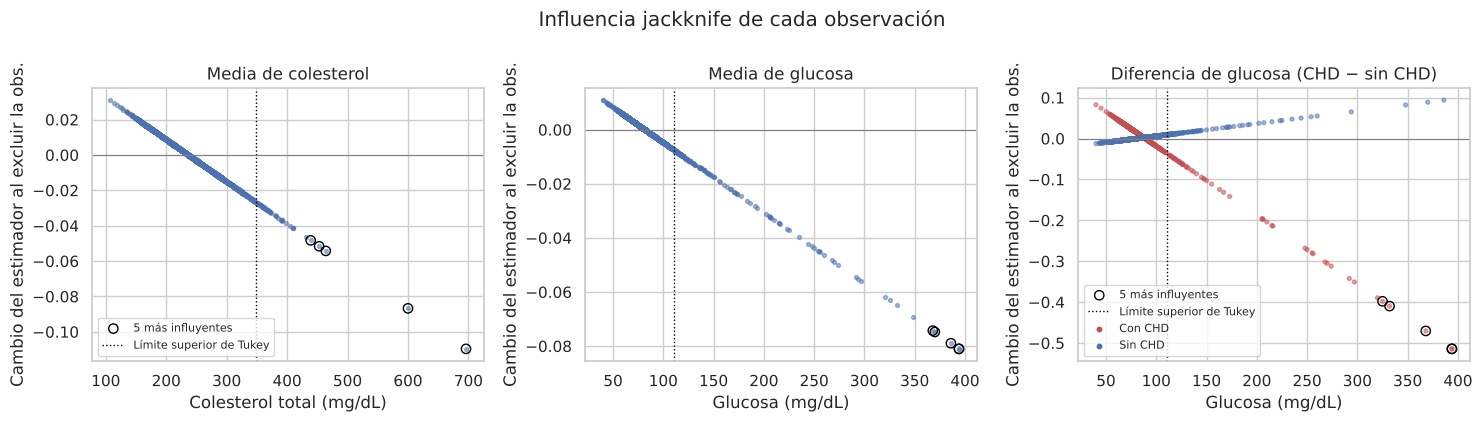

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
paneles = [("totChol", jk_media["totChol"], df["totChol"].dropna().to_numpy(float), "Media de colesterol"),
           ("glucose", jk_media["glucose"], df["glucose"].dropna().to_numpy(float), "Media de glucosa"),
           ("glucose", None, None, "Diferencia de glucosa (CHD − sin CHD)")]
for ax, (v, jm, x, titulo) in zip(axes, paneles):
    if jm is None:
        j = jk_dif["glucose"]
        x, cambio = j["valores"], j["loo"] - j["theta"]
        colores = np.where(j["grupo"] == 1, COLORES["riesgo"], COLORES["principal"])
    else:
        cambio = jm["loo"] - jm["estimacion"]
        colores = COLORES["principal"]
    inf, sup = limites_tukey(df[v])
    ax.scatter(x, cambio, s=8, alpha=.5, c=colores)
    top = np.argsort(-np.abs(cambio))[:5]
    ax.scatter(x[top], cambio[top], s=45, facecolors="none", edgecolors="black", label="5 más influyentes")
    ax.axvline(sup, color="black", ls=":", lw=1, label="Límite superior de Tukey")
    ax.axhline(0, color="0.5", lw=.8)
    ax.set(title=titulo, xlabel=NOMBRES[v], ylabel="Cambio del estimador al excluir la obs.")
axes[0].legend(fontsize=8, loc="lower left")
axes[2].scatter([], [], c=COLORES["riesgo"], s=10, label="Con CHD")
axes[2].scatter([], [], c=COLORES["principal"], s=10, label="Sin CHD")
axes[2].legend(fontsize=8, loc="lower left")
plt.suptitle("Influencia jackknife de cada observación", y=1.0)
guardar_figura("p5_fig1_influencia")

### Multicolinealidad (VIF)

La S1 encontró ρ = 0,78 entre presión sistólica y diastólica, y el bloque A confirmó que esa correlación es
la más estable. Interesa saber si ambas pueden analizarse juntas. Se calcula
el factor de inflación de varianza (VIF) de los predictores numéricos candidatos con los umbrales habituales
(< 5 sin problema; 5–10 moderado; > 10 severo).

In [46]:
PREDICTORES = ["age", "sysBP", "diaBP", "totChol", "BMI", "glucose", "cigsPerDay", "heartRate"]


def tabla_vif(columnas):
    X = sm.add_constant(df[columnas].dropna())
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=columnas)


vif = pd.DataFrame({
    "Todos": tabla_vif(PREDICTORES),
    "Sin diaBP": tabla_vif([c for c in PREDICTORES if c != "diaBP"]),
    "Sin sysBP": tabla_vif([c for c in PREDICTORES if c != "sysBP"]),
})
vif.index = [NOMBRES[c] for c in vif.index]
vif["Nivel (todos)"] = pd.cut(vif["Todos"], [0, 5, 10, np.inf], labels=["< 5", "5–10", "> 10"])
d_sys, d_dia = RESULTADOS_S1["diferencias"]["sysBP"]["g"], RESULTADOS_S1["diferencias"]["diaBP"]["g"]
print(f"Tamaño de efecto respecto de CHD en la S1: sistólica g = {d_sys} | diastólica g = {d_dia}")
guardar_tabla(vif.round(2), "p5_vif")

Tamaño de efecto respecto de CHD en la S1: sistólica g = 0.62 | diastólica g = 0.41


,Todos,Sin diaBP,Sin sysBP,Nivel (todos)
IMC (kg/m²),1.1900,1.1300,1.1900,< 5
Edad (años),1.3200,1.2800,1.1600,< 5
Cigarrillos por día,1.0500,1.0500,1.0500,< 5
Presión diastólica (mmHg),2.8500,NaN,1.2500,< 5
Glucosa (mg/dL),1.0400,1.0300,1.0300,< 5
Frecuencia cardíaca (lpm),1.0600,1.0600,1.0600,< 5
Presión sistólica (mmHg),3.1100,1.3600,NaN,< 5
Colesterol total (mg/dL),1.1000,1.1000,1.1000,< 5


**Interpretación 5.1.** El jackknife reproduce exactamente el error estándar clásico de las cuatro medias (por
ejemplo, 0,338 mmHg en presión sistólica y 0,386 mg/dL en glucosa) y su sesgo es nulo. Esto confirma que los
IC t de la S1 usan el error estándar correcto. Ninguna observación individual mueve las medias de forma
apreciable: el caso más influyente (colesterol de 696 mg/dL) cambia la media del colesterol en solo 0,11 mg/dL,
la sexta parte de su error estándar. Lo mismo ocurre con la glucosa de 394 mg/dL (0,08 mg/dL) y la presión
sistólica de 295 mmHg (0,04 mmHg). Las cinco observaciones más influyentes de cada media son atípicos de Tukey
de la cola superior.

La diferencia de glucosa es el estimador con mayor aceleración (a = 0,029, frente a 0,006 en la diferencia de
presión sistólica y ≤ 0,003 en las medias de edad, presión y colesterol). Por eso el IC BCa del bloque A es
asimétrico y se aleja del IC de Welch. Además, sus observaciones más influyentes son pacientes **con CHD** y
glucosa muy alta (394, 394, 368, 332 y 325 mg/dL), y cada uno, por sí solo, reduce la diferencia en 0,4 a
0,5 mg/dL al excluirlo. El efecto conjunto de esos pocos casos se cuantifica en 5.2.

**Multicolinealidad.** Todos los VIF están bajo 5, por lo que no hay multicolinealidad severa según los
umbrales habituales. Aun así, presión sistólica (3,11) y diastólica (2,85) son las únicas que se inflan
mutuamente: al quitar la diastólica, el VIF de la sistólica baja a 1,36. Se recomienda conservar
la **presión sistólica**, porque tiene el mayor tamaño de efecto respecto de CHD en la S1 (g = 0,62 frente a
0,41), su diferencia entre grupos es la más robusta de este análisis y su inclusión sola elimina la
redundancia.

## 5.2 Sensibilidad a outliers

Para cada variable se comparan cinco estimadores del centro: la media de la S1 (IC t), la media sin los
atípicos de Tukey (IC t), la media sin las 5 observaciones más influyentes del jackknife, la media recortada al
5 % (IC BCa) y la mediana (IC bootstrap: BCa, o percentil cuando BCa no es calculable). La media y la mediana estiman parámetros distintos cuando la distribución
es asimétrica, así que la mediana se informa como descriptor alternativo y no entra en el cálculo del
"cambio" de la media. Los atípicos se cuentan con el mismo criterio IQR de la S1.

In [47]:
filas_out, ic_out = [], {}
for s, v in enumerate(VARIABLES):
    x = df[v].dropna().to_numpy(float)
    atip = es_atipico(pd.Series(x)).to_numpy()
    inf_t, sup_t = limites_tukey(x)
    media = x.mean()
    top5 = np.argsort(-np.abs(jk_media[v]["estimacion"] - jk_media[v]["loo"]))[:5]
    sin_top5 = np.delete(x, top5)
    rec_ic = ic_bca(x, media_recortada, seed=SEED + 20 + s)
    med_ic = ic_bca(x, np.median, seed=SEED + 30 + s)
    ref = RESULTADOS_S1["ic"][CLAVE_S1[v]]["ic"] if v in CLAVE_S1 else ic_t(x)
    ic_out[v] = {
        "Media (S1, IC t)": (media, *ref),
        "Media sin atípicos (IC t)": (x[~atip].mean(), *ic_t(x[~atip])),
        "Media sin 5 más influyentes (IC t)": (sin_top5.mean(), *ic_t(sin_top5)),
        "Media recortada 5 % (IC BCa)": (media_recortada(x), *rec_ic),
        "Mediana (IC bootstrap)": (np.median(x), *med_ic),
    }
    filas_out.append({
        "Variable": NOMBRES[v], "n": len(x), "Método atípicos": "IQR (Tukey)",
        "Límite inf.": inf_t, "Límite sup.": sup_t, "n atípicos": int(atip.sum()),
        "% atípicos": 100 * atip.mean(), "Máximo": x.max(),
        "Media": media, "Media sin atípicos": x[~atip].mean(),
        "Δ % sin atípicos": cambio_pct(x[~atip].mean(), media),
        "Media sin 5 influyentes": sin_top5.mean(), "Δ % sin 5 influyentes": cambio_pct(sin_top5.mean(), media),
        "Media recortada 5 %": media_recortada(x), "Δ % recortada": cambio_pct(media_recortada(x), media),
        "Mediana": np.median(x), "Δ % mediana": cambio_pct(np.median(x), media),
    })
tabla_out = pd.DataFrame(filas_out).set_index("Variable")
guardar_tabla(tabla_out.round(3), "p5_outliers")

  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


  BCa no calculable para median; se usa percentil


,n,Método atípicos,Límite inf.,Límite sup.,n atípicos,% atípicos,Máximo,Media,Media sin atípicos,Δ % sin atípicos,Media sin 5 influyentes,Δ % sin 5 influyentes,Media recortada 5 %,Δ % recortada,Mediana,Δ % mediana
Variable,,,,,,,,,,,,,,,,
Edad (años),4240,IQR (Tukey),21.0000,77.0000,0,0.0000,70.0000,49.5800,49.5800,0.0000,49.5570,-0.0470,49.4410,-0.2800,49.0000,-1.1700
Presión sistólica (mmHg),4240,IQR (Tukey),76.5000,184.5000,126,2.9720,295.0000,132.3550,130.3050,-1.5480,132.2120,-0.1080,130.9040,-1.0960,128.0000,-3.2900
Colesterol total (mg/dL),4190,IQR (Tukey),120.5000,348.5000,56,1.3370,696.0000,236.7000,234.8710,-0.7720,236.3490,-0.1480,235.1700,-0.6460,234.0000,-1.1400
Glucosa (mg/dL),3852,IQR (Tukey),47.0000,111.0000,188,4.8810,394.0000,81.9640,78.4890,-4.2400,81.5730,-0.4760,79.4390,-3.0810,78.0000,-4.8360


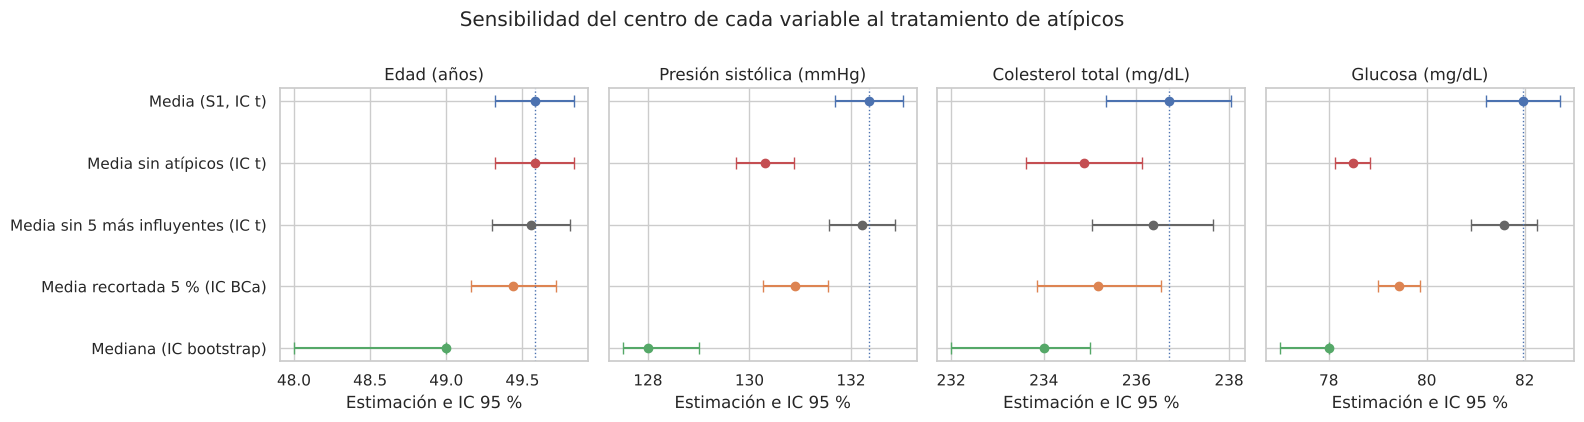

In [48]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
etiquetas = list(next(iter(ic_out.values())).keys())
colores_est = [COLORES["clasico"], COLORES["riesgo"], "0.4", COLORES["percentil"], COLORES["bca"]]
for ax, v in zip(axes, VARIABLES):
    for k, (et, col) in enumerate(zip(etiquetas, colores_est)):
        est, lo, hi = ic_out[v][et]
        ax.errorbar(est, k, xerr=[[est - lo], [hi - est]], fmt="o", color=col, capsize=4, ms=6)
    ax.axvline(ic_out[v]["Media (S1, IC t)"][0], color=COLORES["clasico"], ls=":", lw=1)
    ax.set(title=NOMBRES[v], xlabel="Estimación e IC 95 %")
axes[0].set_yticks(range(len(etiquetas)), etiquetas)
axes[0].invert_yaxis()
plt.suptitle("Sensibilidad del centro de cada variable al tratamiento de atípicos", y=1.0)
guardar_figura("p5_fig2_outliers")

**Las diferencias de la Tabla 4 sin atípicos.** Se repite la prueba de Welch de la S1 (presión sistólica) y la
diferencia de glucosa con cuatro alternativas: sin atípicos de Tukey, sin las 5 observaciones más influyentes
del jackknife de la diferencia, con medias recortadas al 5 % (prueba de Yuen, `ttest_ind(trim=0.05)`) y con
medianas (prueba de la mediana de Mood).

In [49]:
def alternativas_diferencia(v):
    # Diferencia CHD - sin CHD bajo cada tratamiento de atípicos, con su p
    x1, x0 = grupos(v)
    base = welch(x1, x0)
    inf, sup = limites_tukey(df[v])
    filas = [{"Tratamiento": "S1: Welch con todos los datos", **base}]
    a1, a0 = x1[(x1 >= inf) & (x1 <= sup)], x0[(x0 >= inf) & (x0 <= sup)]
    filas.append({"Tratamiento": "Welch sin atípicos de Tukey", **welch(a1, a0)})
    j = jk_dif[v]
    top5 = np.argsort(-np.abs(j["theta"] - j["loo"]))[:5]
    quitar = np.zeros(len(j["loo"]), bool)
    quitar[top5] = True
    filas.append({"Tratamiento": "Welch sin 5 más influyentes",
                  **welch(x1[~quitar[:len(x1)]], x0[~quitar[len(x1):]])})
    yuen = stats.ttest_ind(x1, x0, equal_var=False, trim=0.05)
    filas.append({"Tratamiento": "Yuen (medias recortadas 5 %)",
                  "dif": media_recortada(x1) - media_recortada(x0), "t": yuen.statistic, "p": yuen.pvalue,
                  "n1": len(x1), "n0": len(x0)})
    mood = stats.median_test(x1, x0)
    filas.append({"Tratamiento": "Mood (medianas)", "dif": np.median(x1) - np.median(x0), "p": mood.pvalue,
                  "n1": len(x1), "n0": len(x0)})
    t = pd.DataFrame(filas)
    t.insert(0, "Variable", NOMBRES[v])
    t["Δ % vs S1"] = cambio_pct(t["dif"], base["dif"])
    t["Decisión"] = np.where(t["p"] < ALPHA, "Se rechaza H₀", "No se rechaza H₀")
    return t


tabla_dif = pd.concat([alternativas_diferencia("sysBP"), alternativas_diferencia("glucose")])
tabla_dif = tabla_dif.set_index(["Variable", "Tratamiento"])
guardar_tabla(tabla_dif, "p5_diferencias_sin_atipicos")

dif  ic_inf  \
Variable                 Tratamiento                                     
Presión sistólica (mmHg) S1: Welch con todos los datos 13.2815 11.1111   
                         Welch sin atípicos de Tukey    9.6643  7.9187   
                         Welch sin 5 más influyentes   12.4663 10.4099   
                         Yuen (medias recortadas 5 %)  13.1465     NaN   
                         Mood (medianas)               12.0000     NaN   
Glucosa (mg/dL)          S1: Welch con todos los datos  8.3292  4.9508   
                         Welch sin atípicos de Tukey    0.8328 -0.2054   
                         Welch sin 5 más influyentes    6.0067  3.2958   
                         Yuen (medias recortadas 5 %)   3.3376     NaN   
                         Mood (medianas)                1.0000     NaN   

                                                        ic_sup       t      p  \
Variable                 Tratamiento                                            
Presión sistólica (mmHg) S1: Welch con todos los datos 15.4519 12.0123 0.0000   
                         Welch sin atípicos de Tukey   11.4099 10.8683 0.0000   
                         Welch sin 5 más influyentes   14.5227 11.8998 0.0000   
                         Yuen (medias recortadas 5 %)      NaN 12.0139 0.0000   
                         Mood (medianas)                   NaN     NaN 0.0000   
Glucosa (mg/dL)          S1: Welch con todos los datos 11.7075  4.8414 0.0000   
                         Welch sin atípicos de Tukey    1.8709  1.5748 0.1157   
                         Welch sin 5 más influyentes    8.7175  4.3508 0.0000   
                         Yuen (medias recortadas 5 %)      NaN  3.7771 0.0002   
                         Mood (medianas)                   NaN     NaN 0.0708   

                                                            d   n1    n0  \
Variable                 Tratamiento                                       
Presión sistólica (mmHg) S1: Welch con todos los datos 0.6173  644  3596   
                         Welch sin atípicos de Tukey   0.5238  594  3520   
                         Welch sin 5 más influyentes   0.5879  639  3596   
                         Yuen (medias recortadas 5 %)     NaN  644  3596   
                         Mood (medianas)                  NaN  644  3596   
Glucosa (mg/dL)          S1: Welch con todos los datos 0.3504  594  3258   
                         Welch sin atípicos de Tukey   0.0756  537  3127   
                         Welch sin 5 más influyentes   0.2781  589  3258   
                         Yuen (medias recortadas 5 %)     NaN  594  3258   
                         Mood (medianas)                  NaN  594  3258   

                                                        Δ % vs S1  \
Variable                 Tratamiento                                
Presión sistólica (mmHg) S1: Welch con todos los datos     0.0000   
                         Welch sin atípicos de Tukey     -27.2349   
                         Welch sin 5 más influyentes      -6.1378   
                         Yuen (medias recortadas 5 %)     -1.0159   
                         Mood (medianas)                  -9.6486   
Glucosa (mg/dL)          S1: Welch con todos los datos     0.0000   
                         Welch sin atípicos de Tukey     -90.0018   
                         Welch sin 5 más influyentes     -27.8841   
                         Yuen (medias recortadas 5 %)    -59.9283   
                         Mood (medianas)                 -87.9940   

                                                                Decisión  
Variable                 Tratamiento                                      
Presión sistólica (mmHg) S1: Welch con todos los datos     Se rechaza H₀  
                         Welch sin atípicos de Tukey       Se rechaza H₀  
                         Welch sin 5 más influyentes       Se rechaza H₀  
                         Yuen (medias recortadas 5 %)      Se rechaza H₀  
     

**Interpretación 5.2.** Las medias de **edad, presión sistólica y colesterol** son robustas: con cualquier
tratamiento de atípicos cambian como máximo un 1,6 %, es decir, 1 a 2 unidades, sin relevancia práctica. La edad
no tiene atípicos y sus cinco valores más influyentes cambian la media en 0,005 años. Como con n ≈ 4.200 los IC
son muy estrechos, en presión sistólica la media sin atípicos y la media recortada quedan fuera del IC de la S1.
Esto refleja que la media incluye la cola superior de una variable asimétrica, no un problema del estimador.
La **glucosa** muestra el mismo patrón con más intensidad: −4,2 % sin atípicos, −3,1 % con la media recortada, y
mediana de 78 mg/dL frente a una media de 82. Con la regla del 10 % su media se clasifica como robusta, pero el
"centro" de la glucosa depende claramente de cómo se traten sus 188 atípicos (4,9 %, todos por encima de
111 mg/dL), y eso pesa mucho más en la comparación entre grupos.

La **diferencia de presión sistólica** sigue siendo significativa (p < 0,001) con los cinco tratamientos y su
magnitud va de 9,7 a 13,3 mmHg. Al excluir los 126 atípicos de Tukey (> 184,5 mmHg), la diferencia baja un 27 % y
la d de Cohen pasa de 0,62 a 0,52. No es un artefacto: esos valores son presiones de hipertensión severa,
clínicamente plausibles y concentradas en el grupo con CHD, y quitarlos elimina parte de la señal real. La
existencia y la dirección del efecto son robustas; su magnitud depende de la cola superior.

La **diferencia de glucosa** no es robusta. Sin los atípicos de Tukey cae de 8,33 a 0,83 mg/dL
(IC [−0,21; 1,87], p = 0,116), y la diferencia de medianas es de solo 1 mg/dL (prueba de Mood, p = 0,071).
Con medias recortadas al 5 % se mantiene significativa (3,34 mg/dL, p < 0,001), pero es un 60 % menor. La
diferencia que reportó la S1 es real en promedio, pero se concentra en una minoría de pacientes con glucosa
alta (rango diabético). Para el paciente típico, la glucosa no difiere entre quienes desarrollan CHD y
quienes no.

## 5.3 Sensibilidad a supuestos y a la limpieza

### a) Pearson vs Spearman, con y sin atípicos

La S1 eligió Spearman porque varias variables son asimétricas. Si Pearson y Spearman coinciden y ninguno
cambia al quitar atípicos, la correlación no depende del supuesto de linealidad/normalidad ni de valores
extremos. Se agrega el par colesterol–glucosa, que el bloque A clasificó como inestable.

In [50]:
PARES = list(RESULTADOS_S1["correlaciones"]) + [("totChol", "glucose")]
filas_corr = []
for x_n, y_n in PARES:
    d = df[[x_n, y_n]].dropna()
    sin = d[~(es_atipico(d[x_n]) | es_atipico(d[y_n]))]
    fila = {"Par": f"{NOMBRES[x_n]} – {NOMBRES[y_n]}",
            "ρ S1": RESULTADOS_S1["correlaciones"].get((x_n, y_n), np.nan), "n": len(d), "n sin atípicos": len(sin)}
    for etiqueta, datos in [("todos", d), ("sin atípicos", sin)]:
        fila[f"Spearman {etiqueta}"] = stats.spearmanr(datos[x_n], datos[y_n]).statistic
        fila[f"Pearson {etiqueta}"] = stats.pearsonr(datos[x_n], datos[y_n]).statistic
    filas_corr.append(fila)
tabla_corr = pd.DataFrame(filas_corr).set_index("Par")
tabla_corr["Pearson − Spearman"] = tabla_corr["Pearson todos"] - tabla_corr["Spearman todos"]
tabla_corr["Δ Spearman sin atípicos"] = tabla_corr["Spearman sin atípicos"] - tabla_corr["Spearman todos"]
tabla_corr["Δ Pearson sin atípicos"] = tabla_corr["Pearson sin atípicos"] - tabla_corr["Pearson todos"]
guardar_tabla(tabla_corr.round(4), "p5_pearson_spearman")

,ρ S1,n,n sin atípicos,Spearman todos,Pearson todos,Spearman sin atípicos,Pearson sin atípicos,Pearson − Spearman,Δ Spearman sin atípicos,Δ Pearson sin atípicos
Par,,,,,,,,,,
Presión sistólica (mmHg) – Presión diastólica (mmHg),0.7800,4240,4082,0.7776,0.7840,0.7592,0.7546,0.0063,-0.0184,-0.0294
Edad (años) – Presión sistólica (mmHg),0.3900,4240,4114,0.3910,0.3941,0.3649,0.3653,0.0031,-0.0261,-0.0287
IMC (kg/m²) – Presión diastólica (mmHg),0.3700,4221,4049,0.3747,0.3774,0.3465,0.3321,0.0026,-0.0282,-0.0453
Colesterol total (mg/dL) – Glucosa (mg/dL),NaN,3842,3611,0.0299,0.0465,0.0174,0.0240,0.0166,-0.0125,-0.0226


### b) Imputación de la glucosa

La S1 usó casos disponibles para la glucosa (388 faltantes, 9,2 %). Se compara con dos imputaciones simples:
la mediana global y la
mediana según el diagnóstico de diabetes, ya que los diabéticos tienen glucosas mucho más altas.

In [51]:
glu = df["glucose"]
med_diab = df.groupby("diabetes")["glucose"].median()
versiones_glu = {
    "Casos disponibles (S1)": glu,
    "Imputación por mediana global": glu.fillna(glu.median()),
    "Imputación por mediana según diabetes": glu.fillna(df["diabetes"].map(med_diab)),
}
print("Mediana de glucosa según diabetes:", med_diab.to_dict(),
      "| faltantes en diabéticos:", int(glu.isna()[df["diabetes"] == 1].sum()))
filas_imp = []
for nombre, serie in versiones_glu.items():
    x = serie.dropna().to_numpy(float)
    lo, hi = ic_t(x)
    w = welch(*grupos("glucose", df.assign(glucose=serie)))
    filas_imp.append({"Versión": nombre, "n": len(x), "Media": x.mean(), "DE": x.std(ddof=1),
                      "Amplitud IC 95 % media": hi - lo, "Dif. CHD − sin CHD": w["dif"],
                      "IC dif. inf.": w["ic_inf"], "IC dif. sup.": w["ic_sup"], "p Welch": w["p"]})
tabla_imp = pd.DataFrame(filas_imp).set_index("Versión")
tabla_imp["Δ % dif. vs S1"] = cambio_pct(tabla_imp["Dif. CHD − sin CHD"], tabla_imp["Dif. CHD − sin CHD"].iloc[0])
guardar_tabla(tabla_imp.round(4), "p5_imputacion_glucosa")

Mediana de glucosa según diabetes: {0: 78.0, 1: 145.0} | faltantes en diabéticos: 4


,n,Media,DE,Amplitud IC 95 % media,Dif. CHD − sin CHD,IC dif. inf.,IC dif. sup.,p Welch,Δ % dif. vs S1
Versión,,,,,,,,,
Casos disponibles (S1),3852,81.9637,23.9543,1.5134,8.3292,4.9508,11.7075,0.0000,0.0000
Imputación por mediana global,4240,81.6009,22.8603,1.3766,7.7263,4.6045,10.8481,0.0000,-7.2379
Imputación por mediana según diabetes,4240,81.6642,22.9428,1.3815,7.8971,4.7656,11.0286,0.0000,-5.1872


### c) Imputación de cigarrillos por día

La S1 imputó los 29 faltantes de `cigsPerDay` (todos fumadores) con la mediana de los fumadores (20). Se
compara con excluir esos casos (datos originales, `cargar_datos(limpio=False)`).

In [52]:
raw = cargar_datos(limpio=False)
filas_cig = []
for nombre, datos in [("Imputación con mediana 20 (S1)", df), ("Excluir los 29 casos", raw.dropna(subset=["cigsPerDay"]))]:
    fum = datos.loc[datos["currentSmoker"] == 1, "cigsPerDay"]
    w = welch(*grupos("cigsPerDay", datos))
    filas_cig.append({"Versión": nombre, "n": len(datos), "Media fumadores": fum.mean(),
                      "DE fumadores": fum.std(), "Dif. CHD − sin CHD": w["dif"], "IC inf.": w["ic_inf"],
                      "IC sup.": w["ic_sup"], "p Welch": w["p"],
                      "Spearman con CHD": stats.spearmanr(datos["cigsPerDay"], datos["TenYearCHD"]).statistic})
tabla_cig = pd.DataFrame(filas_cig).set_index("Versión")
tabla_cig["Δ % dif. vs S1"] = cambio_pct(tabla_cig["Dif. CHD − sin CHD"], tabla_cig["Dif. CHD − sin CHD"].iloc[0])
assert round(tabla_cig["Dif. CHD − sin CHD"].iloc[0], 2) == RESULTADOS_S1["diferencias"]["cigsPerDay"]["dif"]
guardar_tabla(tabla_cig.round(4), "p5_imputacion_cigs")

,n,Media fumadores,DE fumadores,Dif. CHD − sin CHD,IC inf.,IC sup.,p Welch,Spearman con CHD,Δ % dif. vs S1
Versión,,,,,,,,,
Imputación con mediana 20 (S1),4240,18.3790,10.7925,1.8597,0.7841,2.9353,0.0007,0.0416,0.0000
Excluir los 29 casos,4211,18.3562,10.8663,1.9154,0.8370,2.9937,0.0005,0.0435,2.9917


### d) Perturbación con ruido de medición

Con el método de perturbación, X_sint = X + ε con ε ~ N(0, (δ·s)²), se
agrega ruido proporcional a la desviación estándar de cada variable (δ = 5 % y 10 %) y se recalculan la
diferencia de presión sistólica y las correlaciones de Spearman en B = 10.000 réplicas. Simula errores de
medición, por ejemplo en la toma de presión. Si las conclusiones dependieran de valores exactos o de pocos
casos, el ruido las cambiaría.

In [53]:
DELTAS = [0.05, 0.10]


def spearman_filas(X, Y):
    # Spearman fila a fila (X, Y de forma réplicas × n)
    rx = stats.rankdata(X, axis=1)
    ry = stats.rankdata(Y, axis=1)
    rx -= rx.mean(axis=1, keepdims=True)
    ry -= ry.mean(axis=1, keepdims=True)
    return np.sum(rx * ry, axis=1) / np.sqrt(np.sum(rx**2, axis=1) * np.sum(ry**2, axis=1))


pas = df["sysBP"].to_numpy(float)
perturbacion = {}
for delta in DELTAS:
    rng_p = np.random.default_rng(SEED + int(delta * 100))
    difs = np.empty(B)
    for i0 in range(0, B, 1_000):
        ruido = rng_p.normal(0, delta * pas.std(ddof=1), size=(1_000, len(pas)))
        P = pas + ruido
        difs[i0:i0 + 1_000] = P[:, chd == 1].mean(axis=1) - P[:, chd == 0].mean(axis=1)
    perturbacion[("Diferencia PAS (CHD − sin CHD)", delta)] = difs
    for x_n, y_n in PARES[:3]:
        d = df[[x_n, y_n]].dropna()
        x, y = d[x_n].to_numpy(float), d[y_n].to_numpy(float)
        rhos = np.empty(B)
        for i0 in range(0, B, 500):
            X = x + rng_p.normal(0, delta * x.std(ddof=1), size=(500, len(x)))
            Y = y + rng_p.normal(0, delta * y.std(ddof=1), size=(500, len(y)))
            rhos[i0:i0 + 500] = spearman_filas(X, Y)
        perturbacion[(f"ρ {NOMBRES[x_n]} – {NOMBRES[y_n]}", delta)] = rhos

base_pert = {"Diferencia PAS (CHD − sin CHD)": pas[chd == 1].mean() - pas[chd == 0].mean()}
for x_n, y_n in PARES[:3]:
    d = df[[x_n, y_n]].dropna()
    base_pert[f"ρ {NOMBRES[x_n]} – {NOMBRES[y_n]}"] = stats.spearmanr(d[x_n], d[y_n]).statistic
tabla_pert = pd.DataFrame([
    {"Resultado": r, "δ": delta, "Valor original": base_pert[r], "Media perturbada": v.mean(),
     "DE perturbada": v.std(ddof=1), "P2,5": np.quantile(v, .025), "P97,5": np.quantile(v, .975),
     "Δ % media vs original": cambio_pct(v.mean(), base_pert[r]),
     "Δ % máx. (P2,5 o P97,5)": max(abs(cambio_pct(np.quantile(v, q), base_pert[r])) for q in (.025, .975))}
    for (r, delta), v in perturbacion.items()
]).set_index(["Resultado", "δ"])
guardar_tabla(tabla_pert.round(4), "p5_perturbacion")

,,Valor original,Media perturbada,DE perturbada,"P2,5","P97,5",Δ % media vs original,"Δ % máx. (P2,5 o P97,5)"
Resultado,δ,,,,,,,
Diferencia PAS (CHD − sin CHD),0.0500,13.2815,13.2812,0.0476,13.1876,13.3740,-0.0022,0.7070
ρ Presión sistólica (mmHg) – Presión diastólica (mmHg),0.0500,0.7776,0.7749,0.0009,0.7732,0.7766,-0.3519,0.5728
ρ Edad (años) – Presión sistólica (mmHg),0.0500,0.3910,0.3898,0.0011,0.3875,0.3920,-0.3102,0.8899
ρ IMC (kg/m²) – Presión diastólica (mmHg),0.0500,0.3747,0.3737,0.0012,0.3714,0.3761,-0.2762,0.9070
Diferencia PAS (CHD − sin CHD),0.1000,13.2815,13.2804,0.0942,13.0976,13.4668,-0.0081,1.3957
ρ Presión sistólica (mmHg) – Presión diastólica (mmHg),0.1000,0.7776,0.7669,0.0017,0.7635,0.7703,-1.3724,1.8095
ρ Edad (años) – Presión sistólica (mmHg),0.1000,0.3910,0.3865,0.0023,0.3820,0.3909,-1.1434,2.2923
ρ IMC (kg/m²) – Presión diastólica (mmHg),0.1000,0.3747,0.3703,0.0023,0.3657,0.3749,-1.1824,2.4118


### e) Distribuciones alternativas: sesgo, ECM y cobertura (datos sintéticos)

La glucosa es la variable que más se aleja de la normalidad (asimetría ≈ 6, curtosis ≈ 59). Para saber si el IC t
de la S1 es confiable para ella y qué estimador conviene usar, se generan datos sintéticos desde cuatro
distribuciones ajustadas a la glucosa observada (generación paramétrica y remuestreo de los datos):

| Distribución | Generación |
| --- | --- |
| Normal | N(media, DE) de la glucosa observada |
| Lognormal | exp(N(μ, σ)) con μ y σ del log de la glucosa |
| Empírica | remuestreo con reemplazo de las 3.852 glucosas observadas (incluye sus atípicos) |
| Lognormal contaminada | lognormal con 5 % de valores extremos uniformes entre el límite de Tukey y el máximo (394) |

Para cada distribución y n ∈ {50, 200, 3.852} se simulan B = 10.000 muestras y se calculan la media, la media
recortada al 5 % y la mediana. Cada estimador se compara con *su propio* parámetro poblacional (sesgo, DE y
ECM) y se registra la **cobertura del IC t al 95 %** para la media, que
es el supuesto que usó la S1.

In [54]:
glu_obs = df["glucose"].dropna().to_numpy(float)
mu_log, sd_log = np.log(glu_obs).mean(), np.log(glu_obs).std(ddof=1)
lim_sup_glu = limites_tukey(glu_obs)[1]


def generar(nombre, size, rng_g):
    if nombre == "Normal":
        return rng_g.normal(glu_obs.mean(), glu_obs.std(ddof=1), size)
    if nombre == "Lognormal":
        return np.exp(rng_g.normal(mu_log, sd_log, size))
    if nombre == "Empírica":
        return rng_g.choice(glu_obs, size=size, replace=True)
    x = np.exp(rng_g.normal(mu_log, sd_log, size))
    contaminar = rng_g.random(size) < 0.05
    x[contaminar] = rng_g.uniform(lim_sup_glu, glu_obs.max(), contaminar.sum())
    return x


DISTRIBUCIONES = ["Normal", "Lognormal", "Empírica", "Lognormal contaminada"]
ESTIMADORES = {"Media": lambda X: X.mean(axis=1), "Media recortada 5 %": lambda X: media_recortada(X, axis=1),
               "Mediana": lambda X: np.median(X, axis=1)}
TAMANOS = [50, 200, len(glu_obs)]

# Parámetros poblacionales: exactos para la empírica; con 2.000.000 de draws para las demás
rng_pob = np.random.default_rng(SEED + 99)
poblacion = {}
for dist in DISTRIBUCIONES:
    p = glu_obs if dist == "Empírica" else generar(dist, 2_000_000, rng_pob)
    poblacion[dist] = {"Media": p.mean(), "Media recortada 5 %": media_recortada(p), "Mediana": np.median(p)}

filas_sim = []
for d_i, dist in enumerate(DISTRIBUCIONES):
    for n in TAMANOS:
        rng_s = np.random.default_rng(SEED + 1_000 * (d_i + 1) + n)
        est = {e: np.empty(B) for e in ESTIMADORES}
        cubre = np.empty(B, bool)
        lote = max(1, min(B, 2_000_000 // n))
        for i0 in range(0, B, lote):
            m = min(lote, B - i0)
            X = generar(dist, (m, n), rng_s)
            for e, f in ESTIMADORES.items():
                est[e][i0:i0 + m] = f(X)
            medias, ee = X.mean(axis=1), X.std(axis=1, ddof=1) / np.sqrt(n)
            t_c = stats.t.ppf(1 - ALPHA / 2, n - 1)
            cubre[i0:i0 + m] = np.abs(medias - poblacion[dist]["Media"]) <= t_c * ee
        for e in ESTIMADORES:
            theta = poblacion[dist][e]
            sesgo = est[e].mean() - theta
            filas_sim.append({"Distribución": dist, "n": n, "Estimador": e, "Parámetro": theta,
                              "Sesgo": sesgo, "Sesgo relativo %": 100 * sesgo / theta,
                              "DE": est[e].std(ddof=1), "ECM": np.mean((est[e] - theta) ** 2),
                              "Cobertura IC t 95 %": 100 * cubre.mean() if e == "Media" else np.nan})
tabla_sim = pd.DataFrame(filas_sim).set_index(["Distribución", "n", "Estimador"])
tabla_sim["Eficiencia relativa vs media"] = (
    tabla_sim["DE"].xs("Media", level="Estimador").reindex(tabla_sim.index.droplevel("Estimador")).to_numpy()
    / tabla_sim["DE"]) ** 2
guardar_tabla(tabla_sim.round(4), "p5_sinteticos")

Parámetro   Sesgo  \
Distribución          n    Estimador                                
Normal                50   Media                  81.9381  0.0267   
                           Media recortada 5 %    81.9435  0.0198   
                           Mediana                81.9205  0.0522   
                      200  Media                  81.9381  0.0151   
                           Media recortada 5 %    81.9435  0.0063   
                           Mediana                81.9205  0.0186   
                      3852 Media                  81.9381  0.0272   
                           Media recortada 5 %    81.9435  0.0220   
                           Mediana                81.9205  0.0428   
Lognormal             50   Media                  81.5998  0.0103   
                           Media recortada 5 %    80.9554  0.1505   
                           Mediana                79.9056  0.0588   
                      200  Media                  81.5998  0.0212   
                           Media recortada 5 %    80.9554  0.0353   
                           Mediana                79.9056  0.0371   
                      3852 Media                  81.5998  0.0084   
                           Media recortada 5 %    80.9554  0.0101   
                           Mediana                79.9056  0.0111   
Empírica              50   Media                  81.9637  0.0152   
                           Media recortada 5 %    79.4386  0.3424   
                           Mediana                78.0000  0.1251   
                      200  Media                  81.9637  0.0074   
                           Media recortada 5 %    79.4386  0.0383   
                           Mediana                78.0000 -0.0306   
                      3852 Media                  81.9637  0.0059   
                           Media recortada 5 %    79.4386  0.0096   
                           Mediana                78.0000 -0.0254   
Lognormal contaminada 50   Media                  90.1091  0.1433   
                           Media recortada 5 %    83.0801  1.6702   
                           Mediana                80.9895  0.1340   
                      200  Media                  90.1091  0.0986   
                           Media recortada 5 %    83.0801  0.2940   
                           Mediana                80.9895  0.0610   
                      3852 Media                  90.1091  0.0448   
                           Media recortada 5 %    83.0801  0.0427   
                           Mediana                80.9895  0.0133   

                                                Sesgo relativo %     DE  \
Distribución          n    Estimador                                      
Normal                50   Media                          0.0326 3.3945   
                           Media recortada 5 %            0.0242 3.4246   
                           Mediana                        0.0638 4.1673   
                      200  Media                          0.0185 1.6866   
                           Media recortada 5 %            0.0077 1.7096   
                           Mediana                        0.0228 2.1026   
                      3852 Media                          0.0332 0.3891   
                           Media recortada 5 %            0.0268 0.3958   
                           Mediana                        0.0523 0.4884   
Lognormal             50   Media                          0.0126 2.4018   
                           Media recortada 5 %            0.1859 2.4018   
                           Mediana                        0.0735 2.8952   
                      200  Media                          0.0260 1.1871   
                           Media recortada 5 %            0.0436 1.1868   
                           Mediana                        0.0465 1.4383   
                      3852 Media                          0.0103 0.2723   
                           Media recortada 5 %            0.0125 0.2721   


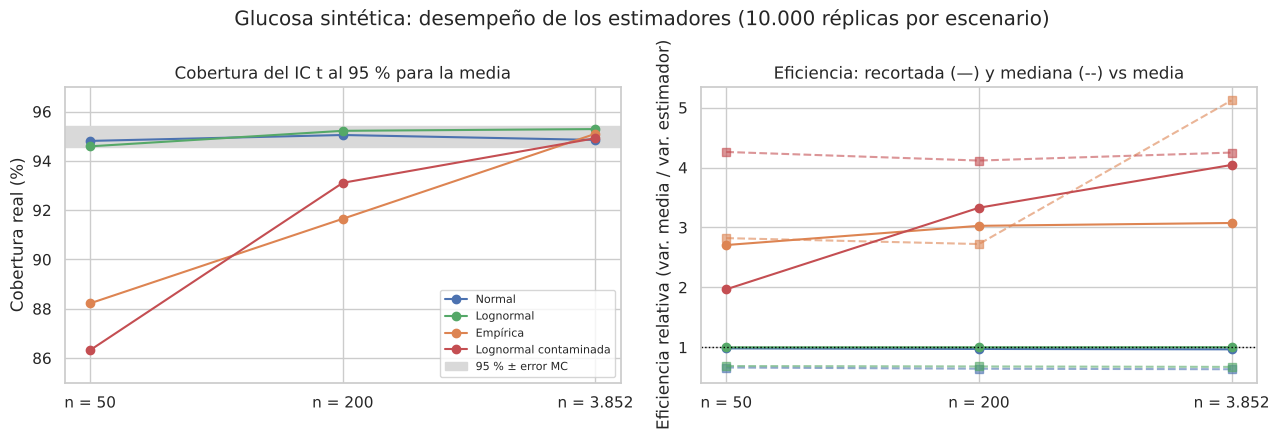

In [55]:
cob = tabla_sim.xs("Media", level="Estimador")["Cobertura IC t 95 %"].unstack("Distribución")[DISTRIBUCIONES]
efi = tabla_sim["Eficiencia relativa vs media"].unstack("Estimador")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
paleta = [COLORES["principal"], COLORES["mediana"], COLORES["percentil"], COLORES["riesgo"]]
for dist, col in zip(DISTRIBUCIONES, paleta):
    axes[0].plot(range(len(TAMANOS)), cob[dist], marker="o", color=col, label=dist)
    axes[1].plot(range(len(TAMANOS)), efi.loc[dist, "Media recortada 5 %"], marker="o", color=col, label=dist)
    axes[1].plot(range(len(TAMANOS)), efi.loc[dist, "Mediana"], marker="s", ls="--", color=col, alpha=.6)
# Banda de error Monte Carlo de una cobertura de 95 % con B réplicas
banda = 1.96 * np.sqrt(.95 * .05 / B) * 100
axes[0].axhspan(95 - banda, 95 + banda, color="0.85", label="95 % ± error MC")
axes[0].set(ylabel="Cobertura real (%)", title="Cobertura del IC t al 95 % para la media", ylim=(85, 97))
axes[1].axhline(1, color="black", lw=1, ls=":")
axes[1].set(ylabel="Eficiencia relativa (var. media / var. estimador)",
            title="Eficiencia: recortada (—) y mediana (--) vs media")
for ax in axes:
    ax.set_xticks(range(len(TAMANOS)), [f"n = {n:,}".replace(",", ".") for n in TAMANOS])
axes[0].legend(fontsize=8, loc="lower right")
plt.suptitle(f"Glucosa sintética: desempeño de los estimadores ({B:,} réplicas por escenario)".replace(",", "."), y=1.0)
guardar_figura("p5_fig4_sinteticos")

### f) Análisis OAT y diagrama de tornado

Cada decisión metodológica se cambia *una a la vez*
(one-at-a-time) y se registra el nuevo valor de la diferencia de la S1. La perturbación con ruido se
representa con su rango P2,5–P97,5. Las barras se ordenan de mayor a menor impacto.

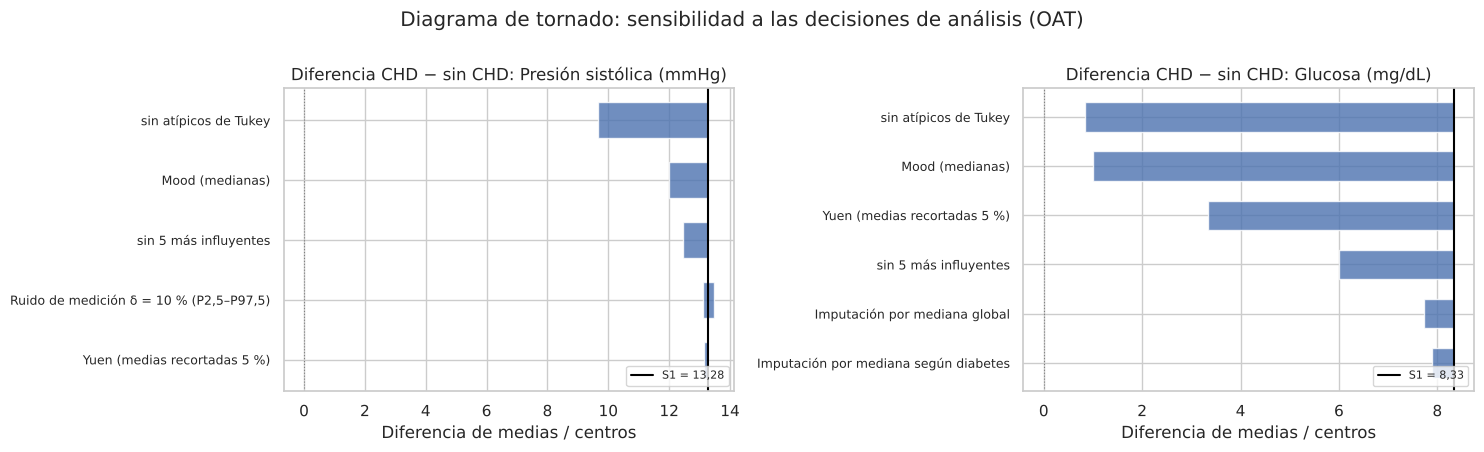

bajo  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.1465   
                                       Ruido de medición δ = 10 % (P2,5–P97,5) 13.0976   
                                       sin 5 más influyentes                   12.4663   
                                       Mood (medianas)                         12.0000   
                                       sin atípicos de Tukey                    9.6643   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    7.8971   
                                       Imputación por mediana global            7.7263   
                                       sin 5 más influyentes                    6.0067   
                                       Yuen (medias recortadas 5 %)             3.3376   
                                       Mood (medianas)                          1.0000   
                                       sin atípicos de Tukey                    0.8328   

                                                                                  alto  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.2815   
                                       Ruido de medición δ = 10 % (P2,5–P97,5) 13.4668   
                                       sin 5 más influyentes                   13.2815   
                                       Mood (medianas)                         13.2815   
                                       sin atípicos de Tukey                   13.2815   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    8.3292   
                                       Imputación por mediana global            8.3292   
                                       sin 5 más influyentes                    8.3292   
                                       Yuen (medias recortadas 5 %)             8.3292   
                                       Mood (medianas)                          8.3292   
                                       sin atípicos de Tukey                    8.3292   

                                                                                 valor  \
Resultado                              Decisión                                          
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            13.1465   
                                       Ruido de medición δ = 10 % (P2,5–P97,5)     NaN   
                                       sin 5 más influyentes                   12.4663   
                                       Mood (medianas)                         12.0000   
                                       sin atípicos de Tukey                    9.6643   
Diferencia de Glucosa (mg/dL)          Imputación por mediana según diabetes    7.8971   
                                       Imputación por mediana global            7.7263   
                                       sin 5 más influyentes                    6.0067   
                                       Yuen (medias recortadas 5 %)             3.3376   
                                       Mood (medianas)                          1.0000   
                                       sin atípicos de Tukey                    0.8328   

                                                                                    p  \
Resultado                              Decisión                                         
Diferencia de Presión sistólica (mmHg) Yuen (medias recortadas 5 %)            0.0000   
                                       Ruido de medición δ = 10 % (P2,5–P97,5)    NaN   
                                       sin 5 más influyentes                   0.0000   
                                       Mood (medianas)                         0.0000   
                                   

In [56]:
def filas_tornado(v):
    base = tabla_dif.loc[(NOMBRES[v], "S1: Welch con todos los datos"), "dif"]
    filas = []
    for trat in tabla_dif.loc[NOMBRES[v]].index[1:]:
        val = tabla_dif.loc[(NOMBRES[v], trat), "dif"]
        filas.append({"Decisión": trat.replace("Welch ", ""), "bajo": min(base, val), "alto": max(base, val),
                      "valor": val, "p": tabla_dif.loc[(NOMBRES[v], trat), "p"]})
    if v == "sysBP":
        r = perturbacion[("Diferencia PAS (CHD − sin CHD)", 0.10)]
        filas.append({"Decisión": "Ruido de medición δ = 10 % (P2,5–P97,5)", "bajo": np.quantile(r, .025),
                      "alto": np.quantile(r, .975), "valor": np.nan, "p": np.nan})
    else:
        for nombre in list(versiones_glu)[1:]:
            val = tabla_imp.loc[nombre, "Dif. CHD − sin CHD"]
            filas.append({"Decisión": nombre, "bajo": min(base, val), "alto": max(base, val), "valor": val,
                          "p": tabla_imp.loc[nombre, "p Welch"]})
    t = pd.DataFrame(filas)
    t["Impacto máx. %"] = 100 * np.maximum(abs(t["bajo"] - base), abs(t["alto"] - base)) / base
    t.insert(0, "Resultado", f"Diferencia de {NOMBRES[v]}")
    return t.sort_values("Impacto máx. %"), base


fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
tornados = []
for ax, v in zip(axes, ["sysBP", "glucose"]):
    t, base = filas_tornado(v)
    tornados.append(t)
    y = np.arange(len(t))
    ax.barh(y, t["alto"] - t["bajo"], left=t["bajo"], color=COLORES["principal"], alpha=.8, height=.6)
    ax.axvline(base, color="black", lw=1.5, label=f"S1 = {base:.2f}".replace(".", ","))
    ax.axvline(0, color="0.5", lw=.8, ls=":")
    ax.set_yticks(y, t["Decisión"], fontsize=9)
    ax.set(title=f"Diferencia CHD − sin CHD: {NOMBRES[v]}", xlabel="Diferencia de medias / centros")
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Diagrama de tornado: sensibilidad a las decisiones de análisis (OAT)", y=1.0)
guardar_figura("p5_fig3_tornado")
guardar_tabla(pd.concat(tornados).set_index(["Resultado", "Decisión"]).round(4), "p5_tornado")

**Interpretación 5.3 (a–f).**

- **a) Pearson vs Spearman.** Ambos coeficientes difieren en menos de 0,02 en los cuatro pares, así que la
  elección de Spearman en la S1 no cambia las conclusiones. Sin atípicos, las tres correlaciones destacadas
  bajan levemente (0,02 a 0,05) y conservan su magnitud. Colesterol–glucosa sigue siendo prácticamente nula
  (0,02 a 0,05). IMC–diastólica es la más sensible: su Pearson sin atípicos cae un 11 %.
- **b) Imputación de glucosa.** Imputar con la mediana reduce la DE (de 23,95 a 22,86) y estrecha el IC de la
  media un 9 % sin aportar información nueva, porque los valores imputados no tienen variabilidad. La
  diferencia según CHD baja de 8,33 a 7,73 mg/dL (mediana global) o 7,90 (mediana según diabetes) y sigue siendo
  significativa. La imputación es la decisión menos influyente sobre la glucosa.
- **c) Imputación de cigarrillos/día.** Excluir los 29 casos imputados cambia la diferencia según CHD en
  un 3 % (1,86 a 1,92 cigarrillos) y el Spearman con CHD de 0,042 a 0,044. La decisión de la S1 es robusta.
- **d) Ruido de medición.** Con ruido del 10 % de la DE, la diferencia de presión sistólica se mantiene entre
  13,10 y 13,47 mmHg (± 1,4 %). Las correlaciones bajan alrededor de un 1 %, que es la atenuación esperable por
  error de medición. Ningún resultado depende de valores exactos.
- **e) Distribuciones alternativas.** Con datos normales o lognormales, el IC t de la media cubre el 95 % para
  cualquier n, y la mediana es menos eficiente que la media (eficiencia ≈ 0,64 ≈ 2/π en la normal, como
  predice la teoría, lo que valida la simulación). Con la distribución **empírica** de la glucosa (que incluye
  sus atípicos), la cobertura del IC t es 88,2 % con n = 50, 91,7 % con n = 200 y 95,1 % con el n de la S1. Con
  la lognormal contaminada, es 86,3 %, 93,1 % y 94,9 %. El IC t de la S1 es confiable con su tamaño muestral,
  pero no en subgrupos pequeños: con n < 200 subestima la incertidumbre de la glucosa. La lognormal ajustada
  cubre bien, así que el problema no es la asimetría sino la **cola pesada**. Con datos empíricos o
  contaminados, la media recortada y la mediana tienen entre 2 y 5 veces menos varianza que la media (el salto
  de la mediana a 5,1 con n grande se debe a que la glucosa se registra en enteros y muchos valores coinciden en
  78).
- **f) Tornado.** En la presión sistólica, ninguna decisión acerca la diferencia a cero (rango 9,7–13,5 mmHg);
  la más influyente es excluir atípicos. En la glucosa, cuatro de las seis decisiones cambian la diferencia en
  más de 25 %, y dos (excluir atípicos y comparar medianas) la dejan cerca de 1 mg/dL y sin significancia. La
  conclusión sobre la glucosa depende sobre todo del tratamiento de la cola, no de la imputación.

## 5.4 Síntesis: resultados robustos vs sensibles

Se resume cada resultado de la S1 con el mayor cambio relativo observado entre las alternativas y si alguna
alternativa cambia la decisión inferencial. La conclusión de tabaquismo se evalúa con la prueba CMH
estratificada por edad (validada por permutación en `02_permutacion.ipynb`).

In [57]:
def clasificar(cambio_max, cambia_decision):
    if cambia_decision:
        return "Sensible"
    return "Robusto" if cambio_max < 10 else "Requiere cautela"


filas_rob = []
# Medias de la Tabla 5 y glucosa: sin atípicos, sin 5 influyentes y recortada
for v in VARIABLES:
    f = tabla_out.loc[NOMBRES[v]]
    cambios = f[["Δ % sin atípicos", "Δ % sin 5 influyentes", "Δ % recortada"]].abs()
    filas_rob.append({"Resultado S1": f"Media de {NOMBRES[v]}", "Valor S1": f["Media"],
                      "Pruebas de robustez": "Sin atípicos, sin 5 influyentes, media recortada 5 %",
                      "Rango alternativo": f"{min(f['Media sin atípicos'], f['Media sin 5 influyentes'], f['Media recortada 5 %']):.2f} – "
                                           f"{max(f['Media sin atípicos'], f['Media sin 5 influyentes'], f['Media recortada 5 %']):.2f}",
                      "Cambio máx. %": cambios.max(), "¿Cambia la decisión?": "No aplica",
                      "Clasificación": clasificar(cambios.max(), False)})
# Diferencias de la Tabla 4
for v, extra in [("sysBP", [tabla_pert.loc[("Diferencia PAS (CHD − sin CHD)", 0.10), "Δ % máx. (P2,5 o P97,5)"]]),
                 ("glucose", list(tabla_imp["Δ % dif. vs S1"].iloc[1:].abs()))]:
    t = tabla_dif.loc[NOMBRES[v]]
    cambios = list(t["Δ % vs S1"].iloc[1:].abs()) + extra
    decision = (t["p"] < ALPHA)
    if v == "glucose":
        decision = pd.concat([decision, tabla_imp["p Welch"] < ALPHA])
    cambia = decision.nunique() > 1
    filas_rob.append({"Resultado S1": f"Diferencia CHD − sin CHD de {NOMBRES[v]}", "Valor S1": t["dif"].iloc[0],
                      "Pruebas de robustez": "Sin atípicos, sin 5 influyentes, Yuen, Mood"
                                             + (", ruido δ = 10 %" if v == "sysBP" else ", imputaciones"),
                      "Rango alternativo": f"{t['dif'].min():.2f} – {t['dif'].max():.2f}",
                      "Cambio máx. %": max(cambios), "¿Cambia la decisión?": "Sí" if cambia else "No",
                      "Clasificación": clasificar(max(cambios), cambia)})
# Tabaquismo: marginal (S1) vs ajustado por edad
tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
tablas = np.stack([pd.crosstab(pd.Categorical(df.loc[tramo_edad == t, "currentSmoker"], [1, 0]),
                               pd.Categorical(df.loc[tramo_edad == t, "TenYearCHD"], [1, 0])).to_numpy()
                   for t in tramo_edad.cat.categories], axis=2)
cmh = StratifiedTable(tablas).test_null_odds(correction=False)
p_s1 = RESULTADOS_S1["pruebas"]["fumar_chd"]["p"]
filas_rob.append({"Resultado S1": "Tabaquismo y CHD: no asociación (χ², p = 0,221)", "Valor S1": p_s1,
                  "Pruebas de robustez": "Permutación, Fisher, ajuste por edad (CMH y permutación estratificada)",
                  "Rango alternativo": f"p = {cmh.pvalue:.1e} (CMH)", "Cambio máx. %": np.nan,
                  "¿Cambia la decisión?": "Sí" if (cmh.pvalue < ALPHA) != (p_s1 < ALPHA) else "No",
                  "Clasificación": clasificar(0, (cmh.pvalue < ALPHA) != (p_s1 < ALPHA))})
# Correlaciones de Spearman
for par in tabla_corr.index[:3]:
    f = tabla_corr.loc[par]
    r_pert = tabla_pert.loc[(f"ρ {par}", 0.10), "Δ % máx. (P2,5 o P97,5)"]
    cambios = [abs(cambio_pct(f[c], f["Spearman todos"])) for c in ["Spearman sin atípicos", "Pearson todos",
                                                                     "Pearson sin atípicos"]] + [r_pert]
    filas_rob.append({"Resultado S1": f"ρ de Spearman {par}", "Valor S1": f["Spearman todos"],
                      "Pruebas de robustez": "Pearson, sin atípicos, ruido δ = 10 %",
                      "Rango alternativo": f"{min(f['Spearman sin atípicos'], f['Pearson todos'], f['Pearson sin atípicos']):.3f} – "
                                           f"{max(f['Spearman sin atípicos'], f['Pearson todos'], f['Pearson sin atípicos']):.3f}",
                      "Cambio máx. %": max(cambios), "¿Cambia la decisión?": "No",
                      "Clasificación": clasificar(max(cambios), False)})
# Imputación de cigsPerDay
c = tabla_cig["Δ % dif. vs S1"].abs().iloc[1]
cambia = (tabla_cig["p Welch"] < ALPHA).nunique() > 1
filas_rob.append({"Resultado S1": "Diferencia CHD − sin CHD de cigarrillos/día (imputación con 20)",
                  "Valor S1": tabla_cig["Dif. CHD − sin CHD"].iloc[0], "Pruebas de robustez": "Excluir los 29 imputados",
                  "Rango alternativo": f"{tabla_cig['Dif. CHD − sin CHD'].iloc[1]:.2f}", "Cambio máx. %": c,
                  "¿Cambia la decisión?": "Sí" if cambia else "No", "Clasificación": clasificar(c, cambia)})
# Supuesto de normalidad del IC t de la glucosa (datos sintéticos, n de la S1 y n = 50)
cob_s1 = cob.loc[len(glu_obs), "Empírica"]
cob_50 = cob.loc[50, "Empírica"]
filas_rob.append({"Resultado S1": "IC t de la media de glucosa (supuesto de normalidad)", "Valor S1": 95.0,
                  "Pruebas de robustez": "Cobertura con datos sintéticos (empírica, lognormal, contaminada)",
                  "Rango alternativo": f"cobertura {cob_50:.1f} % (n = 50) – {cob_s1:.1f} % (n = {len(glu_obs):,})".replace(",", "."),
                  "Cambio máx. %": abs(cambio_pct(cob_s1, 95)), "¿Cambia la decisión?": "No (con el n de la S1)",
                  "Clasificación": clasificar(abs(cambio_pct(cob_s1, 95)), False)})
tabla_rob = pd.DataFrame(filas_rob).set_index("Resultado S1")
guardar_tabla(tabla_rob.round(3), "p5_robustez")

,Valor S1,Pruebas de robustez,Rango alternativo,Cambio máx. %,¿Cambia la decisión?,Clasificación
Resultado S1,,,,,,
Media de Edad (años),49.5800,"Sin atípicos, sin 5 influyentes, media recorta...",49.44 – 49.58,0.2800,No aplica,Robusto
Media de Presión sistólica (mmHg),132.3550,"Sin atípicos, sin 5 influyentes, media recorta...",130.31 – 132.21,1.5480,No aplica,Robusto
Media de Colesterol total (mg/dL),236.7000,"Sin atípicos, sin 5 influyentes, media recorta...",234.87 – 236.35,0.7720,No aplica,Robusto
Media de Glucosa (mg/dL),81.9640,"Sin atípicos, sin 5 influyentes, media recorta...",78.49 – 81.57,4.2400,No aplica,Robusto
Diferencia CHD − sin CHD de Presión sistólica (mmHg),13.2810,"Sin atípicos, sin 5 influyentes, Yuen, Mood, r...",9.66 – 13.28,27.2350,No,Requiere cautela
Diferencia CHD − sin CHD de Glucosa (mg/dL),8.3290,"Sin atípicos, sin 5 influyentes, Yuen, Mood, i...",0.83 – 8.33,90.0020,Sí,Sensible
"Tabaquismo y CHD: no asociación (χ², p = 0,221)",0.2210,"Permutación, Fisher, ajuste por edad (CMH y pe...",p = 2.3e-05 (CMH),NaN,Sí,Sensible
ρ de Spearman Presión sistólica (mmHg) – Presión diastólica (mmHg),0.7780,"Pearson, sin atípicos, ruido δ = 10 %",0.755 – 0.784,2.9630,No,Robusto
ρ de Spearman Edad (años) – Presión sistólica (mmHg),0.3910,"Pearson, sin atípicos, ruido δ = 10 %",0.365 – 0.394,6.6720,No,Robusto


**Síntesis crítica.**

**Conclusiones confiables** (se mantienen con todas las pruebas):

- Las medias de edad, presión sistólica y colesterol de la Tabla 5 y sus IC t (cambios ≤ 1,6 %; el EE jackknife
  coincide con el clásico).
- Quienes desarrollan CHD tienen mayor presión sistólica: el efecto se mantiene en las cinco alternativas, con
  ruido y con permutación (parte 2), siempre con p < 0,001.
- Las correlaciones sistólica–diastólica (0,78) y edad–sistólica (0,39), y la ausencia de correlación entre
  colesterol y glucosa.
- La imputación de `cigsPerDay` con la mediana de fumadores (cambio de 3 %).

**Conclusiones que requieren cautela** (la decisión se mantiene, pero la magnitud cambia más de 10 %):

- La **magnitud** de la diferencia de presión sistólica (entre 9,7 y 13,3 mmHg según cómo se trate la cola
  superior).
- La magnitud de IMC–diastólica (−11 % con Pearson sin atípicos).
- El IC t de la glucosa en subgrupos pequeños (cobertura de 86–92 % con n ≤ 200).

**Conclusiones sensibles** (la decisión cambia):

- **"La glucosa es mayor en quienes desarrollan CHD"**: depende de los ~5 % de pacientes con glucosa > 111 mg/dL;
  sin ellos, o comparando medianas, la diferencia deja de ser significativa.
- **"No hay asociación entre tabaquismo y CHD"**: al ajustar por edad aparece una asociación positiva
  (diferencia de 4,6 pp, p < 0,0001), por lo que el resultado marginal de la S1 no debe usarse como conclusión.

**Observaciones influyentes identificadas:** colesterol de 696 y 600 mg/dL (filas 3160 y 1111), glucosas de 394 mg/dL
(filas 2893 y 2909, ambas con CHD) y presión sistólica de 295 mmHg (fila 481, con CHD). Son valores extremos pero
clínicamente plausibles. Ninguno cambia por sí solo las conclusiones; la sensibilidad viene de la cola en
conjunto (los 188 atípicos de glucosa y los 126 de presión sistólica).

**Recomendaciones metodológicas para la siguiente fase del proyecto:**

1. Usar la **presión sistólica** y no la diastólica cuando se analicen juntas (VIF 3,1 → 1,4 al quitar la
   diastólica; mayor efecto y mayor robustez).
2. **Glucosa:** trabajar con log(glucosa) o con un indicador de hiperglucemia/diabetes en vez de la glucosa en
   bruto, ya que su efecto se concentra en la cola; describirla con la mediana o la media recortada.
3. **Conservar los atípicos** por ser clínicamente plausibles, pero informar los resultados con y sin ellos
   como análisis de sensibilidad, revisando especialmente las observaciones influyentes identificadas.
4. **Tabaquismo ajustado por edad:** no usar la asociación marginal; estimar su efecto controlando por edad,
   por la confusión confirmada en la parte 2.
5. **Imputación de glucosa:** si se imputa, recordar que la imputación por mediana subestima la varianza y
   reportar también el análisis con casos disponibles.
6. Considerar el **desbalance** de `TenYearCHD` (15,2 % de casos) en cualquier análisis posterior.
7. Para los IC, usar **bootstrap** (percentil o BCa, B ≥ 10.000) y evitar IC t para la glucosa en subgrupos con
   n < 200 (por ejemplo, diabetes, n = 109).